# Gavish cancer meta-programmes and epithelial state annotation



Malignant epithelial cells are scored against the 41 published cancer
meta-programmes of Gavish et al. (2023). Scores are converted to robust
z-scores within each technical sample and related meta-programmes are collapsed
into 13 functional programme classes. Every scored cell receives a relative
dominant class (the largest class score); this is not an absolute cell identity.
A separate cluster-level summary is used only for the Figure 1d bubble plot.

## Setup

In [1]:
import hashlib
import gc
import os
import re
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

import scanpy as sc
import anndata as ad

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm, to_hex

from scipy.stats import kruskal



In [2]:
np.random.seed(0)

In [3]:
sc.settings.verbosity = 2

In [4]:
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")

In [5]:
plt.rcParams.update({
    "font.size": 20,
    "axes.titlesize": 20,
    "axes.labelsize": 16,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
})

In [6]:
# paths; set CAP_PROJECT to run this outside the author's machine
project = Path(os.environ.get("CAP_PROJECT", "~/Downloads/1105_Project_Nowotny")).expanduser()

In [7]:
fig_dir = project / "Figures"

In [8]:
df_dir = project / "Dataframe_Saves"

In [9]:
save_dir = project / "Adata_Saves"

In [10]:
notebook_dir = project / "Nina_notebooks_Aug2026"

In [11]:
for d in [fig_dir, df_dir, save_dir]:
    d.mkdir(parents=True, exist_ok=True)

In [12]:
sc.settings.figdir = fig_dir

# show paths relative to the project root
def rel(path):
    return Path(path).relative_to(project)

In [13]:
gavish_file = notebook_dir / "Gavish_cell_state_signature.xlsx"

In [14]:
assert gavish_file.exists(), gavish_file

In [15]:
# labels used by the assignment below
cluster_key = "epi_leiden"

In [16]:
sample_key = "sample"
donor_key = "patient"

In [17]:
no_dominant = "No_dominant_hallmark"

In [18]:
below_score = "below_score_threshold"

In [19]:
below_frequency = "below_frequency_threshold"

In [20]:
not_assigned = [below_score, below_frequency]

## Load

In [21]:
epi = sc.read_h5ad(save_dir / "epithelial_malignancy_scvi.h5ad")

In [22]:
epi

AnnData object with n_obs × n_vars = 129599 × 27357
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'sample_short', 'celltypist_pal_label', 'celltypist_pal_conf', 'cl_annotation', 'cnv_score', 'cnv_signal', 'cnv_high', 'malignant', 'leiden_r0.5', 'leiden_r1.0', 'leiden_r1.2', 'leiden_r1.5', 'epi_leiden', 'epi_leiden_deviance', 'epi_leiden_seed2'
    var: 'gene_id', 'feature_type', 'mt', 'ribo', 'hb', 'n_cells', 'binomial_deviance', 'highly_variable_atlas', 'highly_variable_deviance', 'highly_variable'
    uns: 'celltypist_pal_label_colors', 'cl_annotation_colors', 'condition_colors', 'deviance_neighbors', 'epi_leiden

In [23]:
epi.obs["condition"].value_counts()

condition
ER+      60060
TN       26617
N        26425
HER2+    16497
Name: count, dtype: int64

In [24]:
for col in ["sample", "condition", "malignant", "cnv_score", cluster_key]:
    assert col in epi.obs.columns, col

In [25]:
for layer in ["counts", "lognorm"]:
    assert layer in epi.layers, layer

In [26]:
for key in ["X_scVI", "X_umap"]:
    assert key in epi.obsm, key

In [27]:
epi.shape

(129599, 27357)

In [28]:
epi.obs["malignant"].sum()

np.int64(60546)

## Gavish meta-programme signatures

In [29]:
gavish_sheet = pd.read_excel(gavish_file, sheet_name="Cancer MPs")
gavish_sheet.columns = (
    gavish_sheet.columns.astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
)

In [30]:
gavish_states = {}

In [31]:
mp_id_to_name = {}

In [32]:
for state in gavish_sheet.columns:

    genes = gavish_sheet[state].dropna().astype(str).str.strip()
    genes = genes[genes.ne("")].unique().tolist()

    mp_id = re.match(r"^(MP\d+)\b", state).group(1)

    gavish_states[state] = genes
    mp_id_to_name[mp_id] = state

In [33]:
assert len(gavish_states) == 41

In [34]:
len(gavish_states)

41

In [35]:
# a meta-programme is only scored if enough of its genes survived gene filtering
coverage = []

In [36]:
gavish_used = {}

In [37]:
for state, genes in gavish_states.items():

    present = [g for g in genes if g in epi.var_names]
    fraction = len(present) / len(genes)

    coverage.append({
        "mp": state,
        "n_signature_genes": len(genes),
        "n_present": len(present),
        "fraction_present": fraction,
    })

    if fraction >= 0.50:
        gavish_used[state] = present

In [38]:
coverage = pd.DataFrame(coverage)

In [39]:
dropped = coverage.loc[coverage["fraction_present"] < 0.50]

In [40]:
len(gavish_used), len(gavish_states)

(41, 41)

In [41]:
dropped.round(3)

,mp,n_signature_genes,n_present,fraction_present


In [42]:
coverage.to_csv(df_dir / "gavish_signature_coverage.csv", index=False)

## Scoring



Control-gene-set scoring (Tirosh et al.) is applied independently within each
technical sample to control library-specific expression background. These are
relative within-sample scores; absolute programme amplitude is not compared
between patients. Bin and control-set sizes scale with the number of genes
expressed in each sample.

In [43]:
# scoring reads log-normalised expression only, so the malignant subset and the per-sample copies taken from it do not carry the counts layer
malignant_cells = epi.obs["malignant"].to_numpy()

In [44]:
malignant = ad.AnnData(
    X=epi.layers["lognorm"][malignant_cells].copy(),
    obs=epi.obs.loc[malignant_cells, [sample_key, donor_key, "condition", cluster_key]].copy(),
    var=pd.DataFrame(index=epi.var_names.copy()),
)

In [45]:
malignant.n_obs, malignant.obs[sample_key].nunique()

(60546, 32)

In [46]:
mp_frames = []

In [47]:
skipped_samples = []

In [48]:
for sample, idx in malignant.obs.groupby(sample_key, observed=True).indices.items():

    if len(idx) < 100:
        skipped_samples.append({"sample": sample, "n_malignant": len(idx)})
        continue

    sub = malignant[idx].copy()

    n_expressed = int((sub.X.sum(axis=0) > 0).sum())

    n_bins = min(25, max(5, n_expressed // 200))
    ctrl_size = min(50, max(10, n_expressed // n_bins // 2))

    for state, genes in gavish_used.items():
        sc.tl.score_genes(
            sub,
            gene_list=genes,
            score_name=state,
            ctrl_size=ctrl_size,
            n_bins=n_bins,
            use_raw=False,
            random_state=0,
        )

    mp_frames.append(sub.obs[list(gavish_used)].copy())

    print(f"{sample}: {sub.n_obs:,} cells, {n_bins} bins, ctrl_size {ctrl_size}")

computing score 'MP1 Cell Cycle - G2/M'


    finished (0:00:00)
computing score 'MP2 Cell Cycle - G1/S'
    finished (0:00:00)
computing score 'MP3 Cell Cylce HMG-rich'
    finished (0:00:00)
computing score 'MP4 Chromatin'
    finished (0:00:00)
computing score 'MP5 Stress'
    finished (0:00:00)
computing score 'MP6 Hypoxia'
    finished (0:00:00)
computing score 'MP7 Stress (in vitro)'
    finished (0:00:00)
computing score 'MP8 Proteasomal degradation'
    finished (0:00:00)
computing score 'MP9 Unfolded protein response'
    finished (0:00:00)
computing score 'MP10 Protein maturation'
    finished (0:00:00)
computing score 'MP11 Translation initiation'
    finished (0:00:00)
computing score 'MP12 EMT-I'
    finished (0:00:00)
computing score 'MP13 EMT-II'
    finished (0:00:00)
computing score 'MP14 EMT-III'
    finished (0:00:00)
computing score 'MP15 EMT IV'
    finished (0:00:00)
computing score 'MP16 MES (glioma)'
    finished (0:00:00)
computing score 'MP17 Interferon/MHC-II (I)'
    finished (0:00:00)
computing sco

In [49]:
skipped_samples = pd.DataFrame(skipped_samples)

In [50]:
skipped_samples

,sample,n_malignant
0,GSM4909283_TN-SH0106,11
1,GSM4909284_TN-MH0114-T2,51
2,GSM4909300_ER-MH0032,71


In [51]:
mp_scores = pd.concat(mp_frames)

In [52]:
assert mp_scores.notna().all().all()

In [53]:
scored_cells = mp_scores.index

In [54]:
len(scored_cells), malignant.n_obs

(60413, 60546)

In [55]:
malignant.obs.loc[scored_cells, sample_key].nunique()

29

In [56]:
# robust z-score within sample: median and MAD, so that a few extreme cells do not set the scale for the rest
sample_labels = malignant.obs.loc[scored_cells, sample_key]

In [57]:
robust_frames = []

In [58]:
for sample, idx in sample_labels.groupby(sample_labels, observed=True).indices.items():

    sub = mp_scores.iloc[idx]

    median = sub.median(axis=0)
    mad = (sub - median).abs().median(axis=0).replace(0, np.nan)

    robust_frames.append((sub - median) / (1.4826 * mad))

In [59]:
robust_scores = pd.concat(robust_frames).loc[scored_cells].fillna(0.0)

In [60]:
robust_scores.describe().round(2)

,MP1 Cell Cycle - G2/M,MP2 Cell Cycle - G1/S,MP3 Cell Cylce HMG-rich,MP4 Chromatin,MP5 Stress,MP6 Hypoxia,MP7 Stress (in vitro),MP8 Proteasomal degradation,MP9 Unfolded protein response,MP10 Protein maturation,...,MP32 Skin-pigmentation,MP33 RBCs,MP34 Platelet-activation,MP35 Hemato-related-I,MP36 IG,MP37 Hemato-related-II,MP38 Glutathione,MP39 Metal-response,MP40 PDAC-related,MP41 Unassigned
count,60413.00,60413.00,60413.00,60413.00,60413.00,60413.00,60413.00,60413.00,60413.00,60413.00,...,60413.00,60413.00,60413.00,60413.00,60413.00,60413.00,60413.00,60413.00,60413.00,60413.00
mean,0.87,0.50,0.08,0.09,0.07,0.14,0.07,0.01,0.06,-0.01,...,0.06,-0.02,-0.01,0.02,0.04,0.04,0.09,0.01,0.13,-0.02
std,2.84,1.97,1.16,1.04,1.02,1.16,1.07,1.00,1.09,1.08,...,1.03,1.03,1.04,1.02,1.07,1.02,1.03,1.03,1.13,1.12
min,-3.16,-3.10,-4.93,-3.13,-3.36,-3.62,-3.77,-4.30,-4.31,-5.87,...,-3.57,-5.16,-4.77,-3.51,-4.45,-4.05,-2.95,-4.42,-3.57,-5.68
25%,-0.53,-0.58,-0.65,-0.64,-0.64,-0.62,-0.65,-0.68,-0.65,-0.68,...,-0.65,-0.68,-0.68,-0.66,-0.66,-0.66,-0.64,-0.67,-0.63,-0.67
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,1.12,0.88,0.71,0.72,0.71,0.74,0.70,0.67,0.70,0.67,...,0.71,0.67,0.67,0.69,0.69,0.69,0.72,0.68,0.73,0.67
max,32.74,24.83,8.83,6.11,7.06,10.53,10.74,6.10,12.00,7.72,...,6.73,5.24,6.25,6.10,12.96,5.40,7.69,6.97,15.16,4.93


In [61]:
robust_scores.to_csv(df_dir / "gavish_mp_robust_zscores.csv")

## Programme classes

In [62]:
# related meta-programmes grouped into functional programme classes
gavish_hallmarks = {
    "Cell Cycle": ["MP1", "MP2", "MP3", "MP4"],
    "Stress or Hypoxia": ["MP5", "MP6", "MP7"],
    "Protein Regulation": ["MP8", "MP9", "MP10", "MP11"],
    "Mesenchymal": ["MP12", "MP13", "MP14", "MP15", "MP16"],
    "Interferon and MHC II": ["MP17", "MP18"],
    "Senescence": ["MP19"],
    "Oncogenic": ["MP20"],
    "Respiration": ["MP21"],
    "Secreted": ["MP22", "MP23"],
    "Cilia": ["MP24"],
    "Neural Lineage": ["MP25", "MP26", "MP27", "MP28", "MP29"],
    "Other Lineage": ["MP30", "MP31", "MP32"],
    "Haematological Lineage": ["MP33", "MP34", "MP35", "MP36", "MP37"],
    "Unassigned": ["MP38", "MP39", "MP40", "MP41"],
}

In [63]:
# map the identifiers onto the full column names used in the score table
gavish_hallmarks = {
    hallmark: [mp_id_to_name[mp_id] for mp_id in mp_ids if mp_id in mp_id_to_name]
    for hallmark, mp_ids in gavish_hallmarks.items()
}

In [64]:
assert sum(len(v) for v in gavish_hallmarks.values()) == len(gavish_states)

In [65]:
hallmark_scores = pd.DataFrame(index=robust_scores.index)

In [66]:
for hallmark, mps in gavish_hallmarks.items():

    present = [mp for mp in mps if mp in robust_scores.columns]

    if present:
        hallmark_scores[hallmark] = robust_scores[present].mean(axis=1)

In [67]:
# the Gavish "Unassigned" group (MP38-41) is retained in the scores but is not a candidate identity for a cell or a cluster
candidate_hallmarks = [h for h in hallmark_scores.columns if h != "Unassigned"]

In [68]:
sample_labels = malignant.obs.loc[robust_scores.index, sample_key].astype(str)

In [69]:
# averaging k meta-programmes shrinks the spread by about sqrt(k), so a class built from five would lose to a class built from one. Re-standardising each class within sample removes that, while keeping the noise cancellation that averaging buys.
class_scores = pd.DataFrame(index=robust_scores.index, columns=candidate_hallmarks, dtype=float)

for sample in sample_labels.unique():

    cells = sample_labels.index[sample_labels == sample]
    x = hallmark_scores.loc[cells, candidate_hallmarks]

    median = x.median(axis=0)
    scale = (x - median).abs().median(axis=0) * 1.4826

    class_scores.loc[cells] = (x - median).div(scale.replace(0, np.nan))

class_scores = class_scores.fillna(0.0)

In [70]:
candidate_hallmarks

['Cell Cycle',
 'Stress or Hypoxia',
 'Protein Regulation',
 'Mesenchymal',
 'Interferon and MHC II',
 'Senescence',
 'Oncogenic',
 'Respiration',
 'Secreted',
 'Cilia',
 'Neural Lineage',
 'Other Lineage',
 'Haematological Lineage']

## Cell-level programme assignment (primary)

In [71]:
# The gate is not chosen by eye. It is the lowest class-score threshold at which the conservative (95th-percentile-across-replicates) exceedance rate of an expression-matched random-signature null is at most 10% of the observed rate. The null preserves meta-programme sizes and their gene overlap; only the identity of the genes changes.
target_fdr = 0.10
null_file = save_dir / "gavish_null_by_rep.npy"

In [72]:
expected_sha = (df_dir / "gavish_null_sha256.txt").read_text().strip()
observed_sha = hashlib.sha256(null_file.read_bytes()).hexdigest()

assert observed_sha == expected_sha, "cached null does not match its recorded checksum"

null_by_rep = np.load(null_file)
n_null_replicates = null_by_rep.shape[0]

null_by_rep.shape

(50, 60413)

In [73]:
observed_max = class_scores.max(axis=1)

assert null_by_rep.ndim == 2
assert null_by_rep.shape[1] == len(observed_max), (null_by_rep.shape, len(observed_max))
assert np.isfinite(null_by_rep).all()
assert np.isfinite(observed_max).all()

In [74]:
grid = np.quantile(observed_max, np.linspace(0.50, 0.999, 500))

rows = []

for threshold in grid:

    observed_rate = float((observed_max >= threshold).mean())
    null_rates = (null_by_rep >= threshold).mean(axis=1)

    rows.append({
        "threshold": threshold,
        "observed_rate": observed_rate,
        "null_rate": float(null_rates.mean()),
        "null_rate_p95": float(np.quantile(null_rates, 0.95)),
        "fdr": min(1.0, null_rates.mean() / observed_rate) if observed_rate else np.nan,
        "fdr_upper": min(1.0, np.quantile(null_rates, 0.95) / observed_rate) if observed_rate else np.nan,
        "n_cells": int((observed_max >= threshold).sum()),
    })

activity_calibration = pd.DataFrame(rows)
activity_calibration.to_csv(df_dir / "gavish_activity_calibration.csv", index=False)

In [75]:
eligible = activity_calibration[activity_calibration["fdr_upper"] <= target_fdr]

assert not eligible.empty, (
    "no threshold reaches the target FDR; use the continuous scores as primary "
    "and do not assign categorical states"
)

selected = eligible.iloc[0]
activity_threshold = float(selected["threshold"])
selected_fdr = float(selected["fdr"])
selected_fdr_upper = float(selected["fdr_upper"])

In [76]:
f"{activity_threshold:.3f}", int(selected["n_cells"]), round(float(selected["fdr_upper"]), 3)

('3.374', 7310, 0.1)

In [77]:
sample_labels = malignant.obs.loc[robust_scores.index, sample_key].astype(str)

In [78]:
def assign_cells(class_scores, sample_labels, min_score, min_fraction):
    """activity gate first, then within-sample recurrence among the cells that
    passed it. The two failure modes are kept distinct."""
    top_class = class_scores.idxmax(axis=1)
    top_score = class_scores.max(axis=1)

    passed = top_score >= min_score
    state = top_class.where(passed, below_score)

    for sample in sample_labels.unique():

        cells = sample_labels.index[sample_labels == sample]
        assigned = state.loc[cells][passed.loc[cells]]

        if assigned.empty:
            continue

        # denominator is the cells in this sample that passed the activity gate
        fractions = assigned.value_counts(normalize=True)
        recurrent = set(fractions[fractions >= min_fraction].index)

        state.loc[assigned.index[~assigned.isin(recurrent)]] = below_frequency

    return state, top_score, top_class

In [79]:
frequency_threshold = 0.05

cell_state, cell_top_score, cell_top_class = assign_cells(
    class_scores, sample_labels, activity_threshold, frequency_threshold
)

In [80]:
cell_state.value_counts().to_string()

'below_score_threshold        53103\nCell Cycle                    4384\nbelow_frequency_threshold      986\nInterferon and MHC II          774\nSenescence                     422\nMesenchymal                    275\nSecreted                       169\nCilia                          113\nStress or Hypoxia              104\nOther Lineage                   55\nNeural Lineage                  14\nProtein Regulation               8\nRespiration                      6'

In [81]:
rows = []

for sample in sample_labels.unique():

    cells = (sample_labels == sample).to_numpy()

    observed_rate = float((observed_max[cells] >= activity_threshold).mean())
    null_rates = (null_by_rep[:, cells] >= activity_threshold).mean(axis=1)

    rows.append({
        "sample": sample,
        "condition": malignant.obs.loc[sample_labels.index[cells], "condition"].astype(str).iloc[0],
        "n_cells": int(cells.sum()),
        "observed_rate": observed_rate,
        "null_rate_mean": float(null_rates.mean()),
        "null_rate_p95": float(np.quantile(null_rates, 0.95)),
    })

gate_by_sample = pd.DataFrame(rows).sort_values("observed_rate", ascending=False)
gate_by_sample.to_csv(df_dir / "gavish_activity_gate_by_sample.csv", index=False)

In [82]:
separated = int((gate_by_sample["observed_rate"] > gate_by_sample["null_rate_p95"]).sum())

f"{separated} of {len(gate_by_sample)} tumours above their own null p95"

'29 of 29 tumours above their own null p95'

In [83]:
from scipy.stats import spearmanr

spearmanr(gate_by_sample["n_cells"], gate_by_sample["observed_rate"])

SignificanceResult(statistic=np.float64(-0.004926108374384235), pvalue=np.float64(0.9797669354078311))

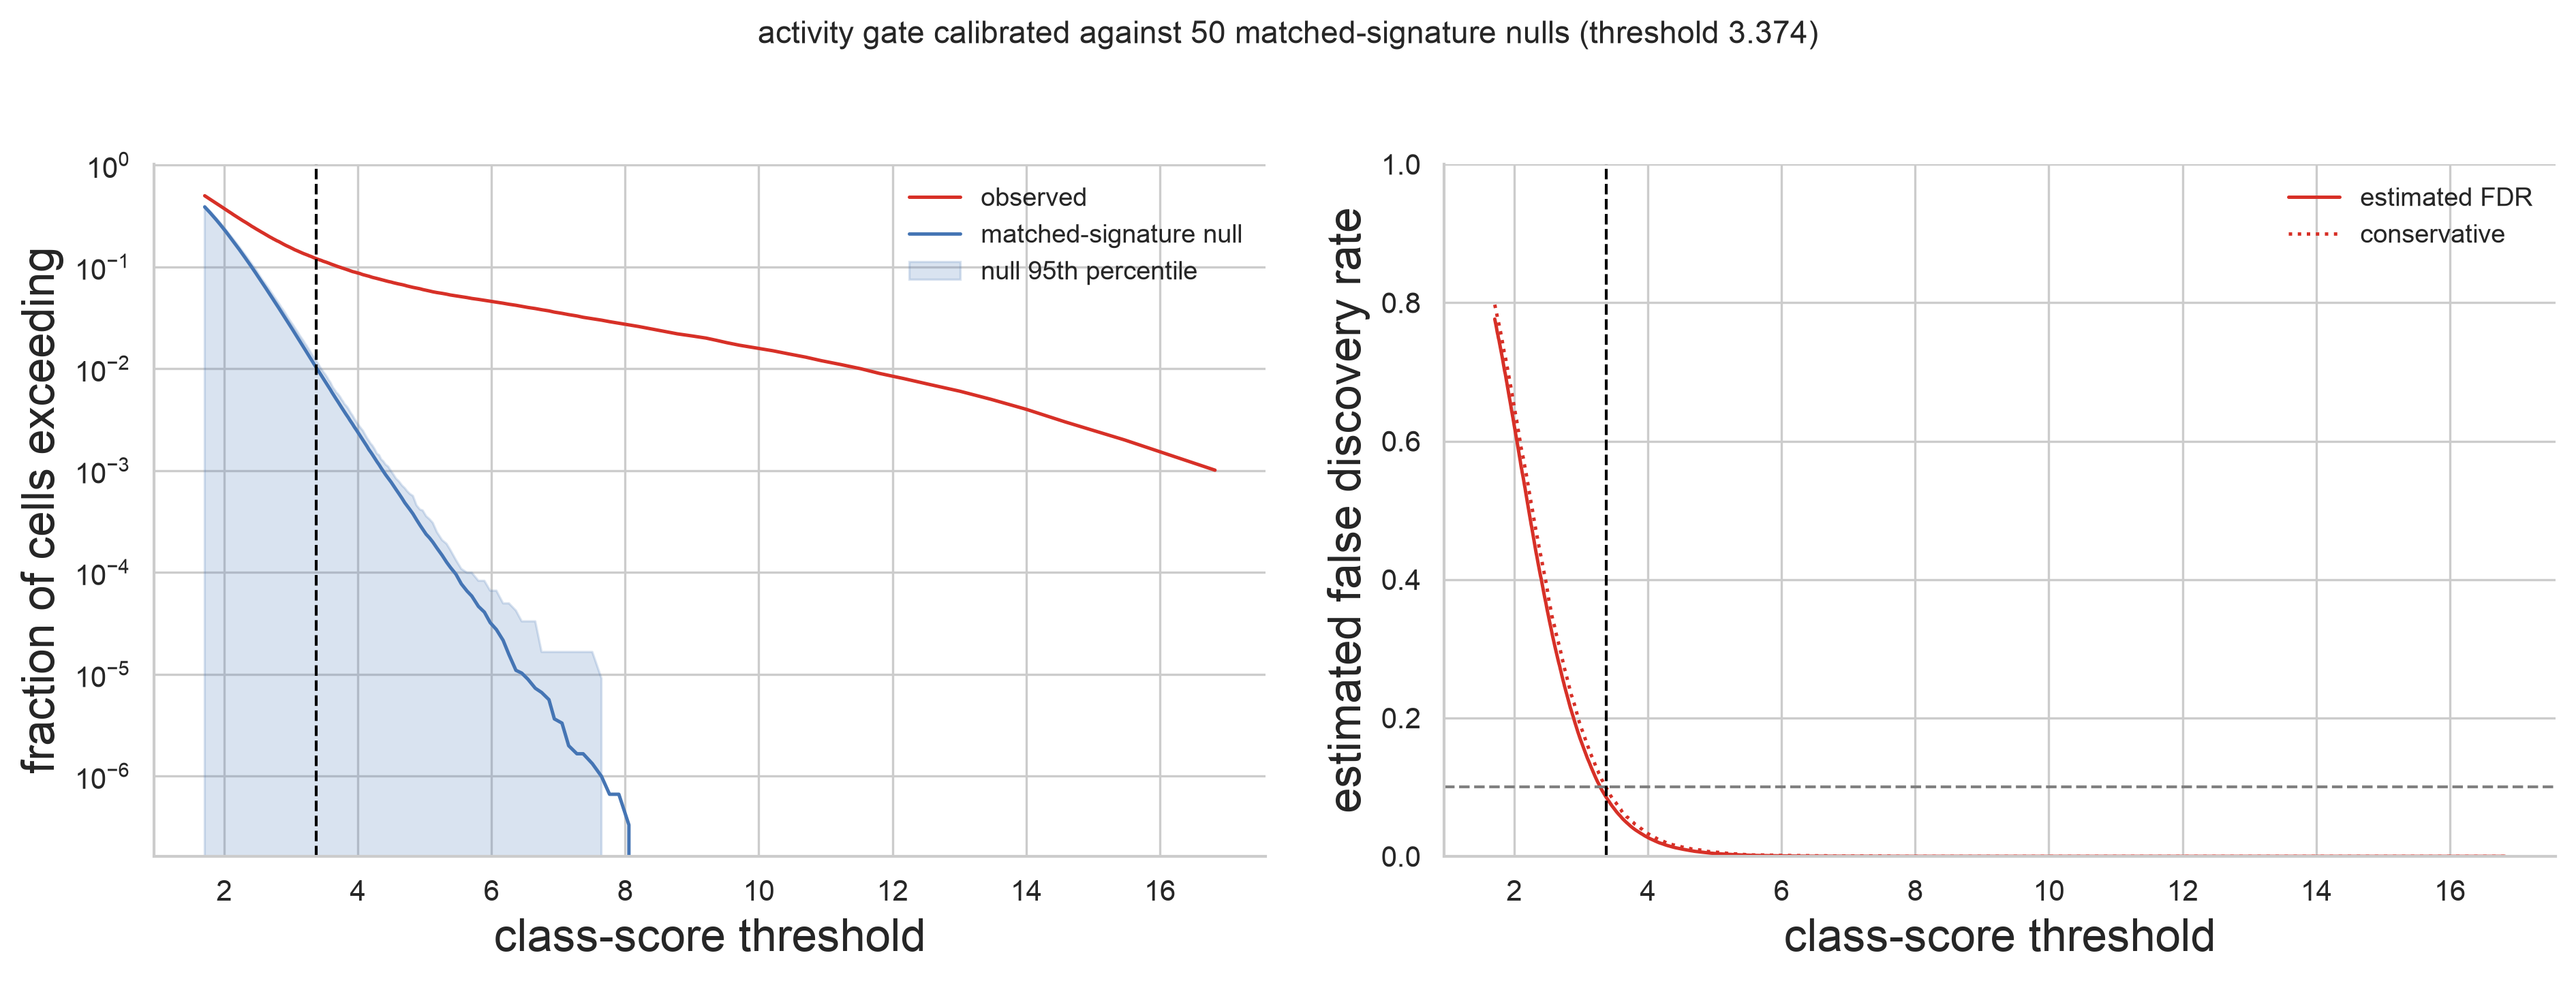

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cal = activity_calibration

axes[0].plot(cal["threshold"], cal["observed_rate"], color="#D73027", label="observed")
axes[0].plot(cal["threshold"], cal["null_rate"], color="#4575B4", label="matched-signature null")
axes[0].fill_between(cal["threshold"], 0, cal["null_rate_p95"], color="#4575B4", alpha=0.2,
                     label="null 95th percentile")
axes[0].axvline(activity_threshold, color="black", linestyle="--", linewidth=1)
axes[0].set_yscale("log")
axes[0].set_xlabel("class-score threshold")
axes[0].set_ylabel("fraction of cells exceeding")
axes[0].legend(frameon=False, fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].plot(cal["threshold"], cal["fdr"], color="#D73027", label="estimated FDR")
axes[1].plot(cal["threshold"], cal["fdr_upper"], color="#D73027", linestyle=":", label="conservative")
axes[1].axhline(target_fdr, color="grey", linestyle="--", linewidth=1)
axes[1].axvline(activity_threshold, color="black", linestyle="--", linewidth=1)
axes[1].set_xlabel("class-score threshold")
axes[1].set_ylabel("estimated false discovery rate")
axes[1].set_ylim(0, 1)
axes[1].legend(frameon=False, fontsize=9)
axes[1].spines[["top", "right"]].set_visible(False)

fig.suptitle(f"activity gate calibrated against {n_null_replicates} matched-signature nulls "
             f"(threshold {activity_threshold:.3f})", fontsize=11)

plt.tight_layout()
plt.savefig(fig_dir / "gavish_activity_calibration.png", dpi=300, bbox_inches="tight")
plt.show()

In [85]:
# every scored malignant cell has a dominant class; these drive the descriptive figures. assigned_cells is the smaller high-activity subset used for sensitivity.
dominant_class = class_scores.idxmax(axis=1)

assigned_cells = cell_state[~cell_state.isin(not_assigned)]

In [86]:
cell_state.value_counts()

below_score_threshold        53103
Cell Cycle                    4384
below_frequency_threshold      986
Interferon and MHC II          774
Senescence                     422
Mesenchymal                    275
Secreted                       169
Cilia                          113
Stress or Hypoxia              104
Other Lineage                   55
Neural Lineage                  14
Protein Regulation               8
Respiration                      6
Name: count, dtype: int64

In [87]:
score_pass = observed_max >= activity_threshold
high_activity_retained = ~cell_state.isin(not_assigned)

assert high_activity_retained.sum() <= score_pass.sum(), (
    "the recurrence filter can only remove cells that passed the activity gate"
)

f"score gate {int(score_pass.sum()):,} -> after 5% recurrence {int(high_activity_retained.sum()):,}"

'score gate 7,310 -> after 5% recurrence 6,324'

In [88]:
# both gates are chosen, so record how the assignment moves around them
rows = []

In [89]:
# sensitivity around the calibrated gate: the threshold is fixed by the null, so this varies it deliberately to show how much the states depend on that choice
rows = []

for threshold in [activity_threshold * f for f in (0.75, 1.0, 1.25)]:
    for fraction in [0.02, 0.05, 0.10]:

        state, _, _ = assign_cells(class_scores, sample_labels, threshold, fraction)
        keep = ~state.isin(not_assigned)

        rows.append({
            "activity_threshold": round(threshold, 3),
            "frequency_threshold": fraction,
            "n_retained": int(keep.sum()),
            "retained_fraction": float(keep.mean()),
            "n_classes": int(state[keep].nunique()),
            "agreement_with_primary": float((state == cell_state).mean()),
        })

assignment_stability = pd.DataFrame(rows)
assignment_stability.to_csv(df_dir / "gavish_assignment_stability.csv", index=False)
assignment_stability.round(3)

,activity_threshold,frequency_threshold,n_retained,retained_fraction,n_classes,agreement_with_primary
0,2.530,0.02,13206,0.219,13,0.880
1,2.530,0.05,11070,0.183,13,0.888
2,2.530,0.10,8221,0.136,9,0.887
3,3.374,0.02,6998,0.116,13,0.989
4,3.374,0.05,6324,0.105,11,1.000
5,3.374,0.10,5782,0.096,10,0.991
6,4.217,0.02,4633,0.077,13,0.955
7,4.217,0.05,4412,0.073,12,0.956
8,4.217,0.10,4233,0.070,10,0.954


In [90]:
cell_assignment_stability = pd.DataFrame(rows)

In [91]:
cell_assignment_stability.round(3)

,activity_threshold,frequency_threshold,n_retained,retained_fraction,n_classes,agreement_with_primary
0,2.530,0.02,13206,0.219,13,0.880
1,2.530,0.05,11070,0.183,13,0.888
2,2.530,0.10,8221,0.136,9,0.887
3,3.374,0.02,6998,0.116,13,0.989
4,3.374,0.05,6324,0.105,11,1.000
5,3.374,0.10,5782,0.096,10,0.991
6,4.217,0.02,4633,0.077,13,0.955
7,4.217,0.05,4412,0.073,12,0.956
8,4.217,0.10,4233,0.070,10,0.954


In [92]:
cell_assignment_stability.to_csv(df_dir / "gavish_cell_assignment_stability.csv", index=False)

## Cluster-level programme assignment 



The Figure 1d legend describes meta-programme activity across epithelial
clusters, so a cluster-level assignment is computed alongside the cell-level
one. It is stored as Gavish_state_cluster and is used only for that panel;
it is not the identity carried by a cell.

In [93]:
cluster_labels = epi.obs.loc[robust_scores.index, cluster_key]

In [94]:
mean_z = robust_scores.groupby(cluster_labels, observed=True).mean()

In [95]:
frac_active = (robust_scores > 1.0).groupby(cluster_labels, observed=True).mean()

In [96]:
def assign_clusters(mean_z, frac_active, active_threshold, min_active_fraction):
    # returns the cluster label series and an audit row per cluster
    labels = pd.Series(no_dominant, index=mean_z.index, dtype="object")
    audit = []

    for cluster in mean_z.index:

        candidates = []

        for hallmark in candidate_hallmarks:

            present = [mp for mp in gavish_hallmarks[hallmark] if mp in mean_z.columns]

            if not present:
                continue

            best_mp = mean_z.loc[cluster, present].idxmax()

            candidates.append((
                hallmark,
                best_mp,
                mean_z.loc[cluster, best_mp],
                frac_active.loc[cluster, best_mp],
            ))

        candidates.sort(key=lambda row: row[2], reverse=True)

        assigned = None

        for hallmark, best_mp, z, fraction in candidates:
            if fraction >= min_active_fraction:
                labels.loc[cluster] = hallmark
                assigned = (hallmark, best_mp, z, fraction)
                break

        if assigned is None and candidates:
            assigned = (no_dominant, candidates[0][1], candidates[0][2], candidates[0][3])

        hallmark, best_mp, z, fraction = assigned

        audit.append({
            "cluster": cluster,
            "hallmark": hallmark,
            "defining_mp": best_mp,
            "mean_z": z,
            "active_fraction": fraction,
        })

    return labels, pd.DataFrame(audit)

In [97]:
cluster_hallmark, assignment_audit = assign_clusters(
    mean_z, frac_active, 1.0, 0.20
)

In [98]:
assignment_audit.round(3)

,cluster,hallmark,defining_mp,mean_z,active_fraction
0,0,Mesenchymal,MP15 EMT IV,0.389,0.268
1,1,Stress or Hypoxia,MP6 Hypoxia,1.506,0.532
2,2,Cell Cycle,MP1 Cell Cycle - G2/M,3.625,0.764
3,3,Interferon and MHC II,MP17 Interferon/MHC-II (I),0.307,0.214
4,4,Secreted,MP22 Secreted I,0.366,0.275
5,5,Haematological Lineage,MP34 Platelet-activation,0.807,0.427
6,6,Secreted,MP22 Secreted I,1.246,0.672
7,7,Stress or Hypoxia,MP6 Hypoxia,1.747,0.691
8,8,Cilia,MP24 Cilia,13.732,1.000
9,9,Mesenchymal,MP14 EMT-III,1.061,0.527


In [99]:
(cluster_hallmark != no_dominant).sum(), len(cluster_hallmark)

(np.int64(17), 17)

In [100]:
assignment_audit.to_csv(df_dir / "gavish_cluster_assignment_audit.csv", index=False)

In [101]:
# the two thresholds are arbitrary, so record how stable the labels are around them
rows = []

In [102]:
for threshold in [0.75, 1.0, 1.25]:

    active = (robust_scores > threshold).groupby(cluster_labels, observed=True).mean()

    for fraction in [0.10, 0.20, 0.30]:

        labels, _ = assign_clusters(mean_z, active, threshold, fraction)

        rows.append({
            "active_threshold": threshold,
            "min_active_fraction": fraction,
            "n_assigned": int((labels != no_dominant).sum()),
            "n_distinct_hallmarks": int(labels[labels != no_dominant].nunique()),
            "agreement_with_primary": float((labels == cluster_hallmark).mean()),
        })

In [103]:
assignment_stability = pd.DataFrame(rows)

In [104]:
assignment_stability.round(3)

,active_threshold,min_active_fraction,n_assigned,n_distinct_hallmarks,agreement_with_primary
0,0.75,0.1,17,7,1.000
1,0.75,0.2,17,7,1.000
2,0.75,0.3,16,7,0.941
3,1.00,0.1,17,7,1.000
4,1.00,0.2,17,7,1.000
5,1.00,0.3,14,7,0.824
6,1.25,0.1,17,7,1.000
7,1.25,0.2,15,7,0.882
8,1.25,0.3,14,7,0.824


In [105]:
assignment_stability.to_csv(df_dir / "gavish_assignment_stability.csv", index=False)

## Write the programme annotation back onto the object

In [106]:
# meta-programme names contain slashes and spaces, which h5 stores will stop accepting, so obs columns are keyed by meta-programme id
mp_name_to_id = {name: mp_id for mp_id, name in mp_id_to_name.items()}

In [107]:
epi.uns["gavish_mp_names"] = {
    mp_name_to_id[mp]: mp for mp in robust_scores.columns
}

In [108]:
for mp in robust_scores.columns:
    column = f"Gavish_{mp_name_to_id[mp]}"
    epi.obs[column] = np.nan
    epi.obs.loc[robust_scores.index, column] = robust_scores[mp].to_numpy()

In [109]:
# the re-standardised class scores, i.e. exactly the matrix the dominant class and the activity gate are computed from. hallmark_scores (mean of member MP z-scores, before re-standardising) is kept only for the Unassigned group.
for hallmark in class_scores.columns:
    column = f"Gavish_{hallmark}"
    epi.obs[column] = np.nan
    epi.obs.loc[class_scores.index, column] = class_scores[hallmark].to_numpy()

epi.obs["Gavish_Unassigned"] = np.nan
epi.obs.loc[hallmark_scores.index, "Gavish_Unassigned"] = (
    hallmark_scores["Unassigned"].to_numpy()
)

In [110]:
# three kinds of cell are distinguished: non-malignant epithelium, malignant cells in a sample with too few cells to score, and scored malignant cells
malignant_mask = epi.obs["malignant"].to_numpy()

In [111]:
# descriptive layer: the dominant relative programme class for every scored malignant cell. This is a relative winner, not evidence of a cell identity.
epi.obs["Gavish_dominant_class"] = "non_malignant"
epi.obs.loc[malignant_mask, "Gavish_dominant_class"] = "not_scored"
epi.obs["Gavish_dominant_score"] = np.nan

In [112]:
epi.obs.loc[class_scores.index, "Gavish_dominant_class"] = (
    class_scores.idxmax(axis=1).to_numpy()
)
epi.obs.loc[class_scores.index, "Gavish_dominant_score"] = (
    class_scores.max(axis=1).to_numpy()
)

In [113]:
check_class = class_scores.idxmax(axis=1)
check_score = class_scores.max(axis=1)

assert (
    epi.obs.loc[class_scores.index, "Gavish_dominant_class"].astype(str)
    == check_class.astype(str)
).all()

assert np.allclose(
    epi.obs.loc[class_scores.index, "Gavish_dominant_score"].to_numpy(dtype=float),
    check_score.to_numpy(dtype=float),
)

# and the saved per-class columns must be the same matrix, not hallmark_scores
saved = epi.obs.loc[class_scores.index, [f"Gavish_{h}" for h in class_scores.columns]]
saved.columns = class_scores.columns

assert np.allclose(saved.to_numpy(dtype=float), class_scores.to_numpy(dtype=float))
assert (saved.idxmax(axis=1).astype(str) == check_class.astype(str)).all()

# the gate must act on exactly the stored dominant score
assert np.array_equal(
    score_pass.to_numpy(),
    epi.obs.loc[class_scores.index, "Gavish_dominant_score"].to_numpy(dtype=float)
    >= activity_threshold,
)

## Class-specific assignment FDR




The global gate asks whether *some* programme is unusually strong. It cannot say which class is right, because the classes do not share a common null tail. Here each class gets its own threshold, calibrated on the event that actually matters: that the class wins the argmax *and* clears its threshold. Classes that never reach the criterion get no confident assignments rather than a relaxed one.

In [114]:
# the per-class null: one matrix of class scores per replicate, not just the maximum
null_class_file = save_dir / "gavish_null_class_scores.npy"

expected_class_sha = (df_dir / "gavish_null_class_sha256.txt").read_text().strip()
observed_class_sha = hashlib.sha256(null_class_file.read_bytes()).hexdigest()

assert observed_class_sha == expected_class_sha, "cached per-class null does not match its checksum"

In [115]:
null_class = np.load(null_class_file)

null_class_order = pd.read_csv(df_dir / "gavish_null_class_order.csv")["class"].tolist()

null_class.shape, len(null_class_order)

((50, 60413, 13), 13)

In [116]:
# the null was generated outside the notebook, so prove it was built from the same scores this notebook just computed rather than trusting the winner counts to agree
external_scores = pd.DataFrame(
    np.load(save_dir / "gavish_observed_class_scores.npy"),
    index=pd.read_csv(df_dir / "gavish_observed_class_index.csv")["cell"],
    columns=null_class_order,
)

In [117]:
assert external_scores.shape == class_scores.shape
assert external_scores.index.equals(class_scores.index)
assert external_scores.columns.equals(class_scores.columns)

assert np.allclose(
    external_scores.to_numpy(dtype=float),
    class_scores.to_numpy(dtype=float),
    rtol=1e-7,
    atol=1e-8,
)

In [118]:
assert null_class.ndim == 3
assert null_class.shape[1:] == class_scores.shape
assert np.isfinite(null_class).all()

In [119]:
# for each class, the lowest threshold at which the conservative FDR of the assignment event is within target. No recurrence filter: the class-specific null already does the work the 5% heuristic was there to approximate, and adding an observed-only filter afterwards would break the correspondence with the calibration.
observed_winner = class_scores.to_numpy().argmax(axis=1)
null_winner = null_class.argmax(axis=2)

In [120]:
rows = []

for position, hallmark in enumerate(class_scores.columns):

    won = observed_winner == position
    if not won.any():
        rows.append({"hallmark": hallmark, "n_winner": 0, "threshold": np.nan,
                     "n_confident": 0, "fdr": np.nan, "fdr_upper": np.nan})
        continue

    selected_row = None

    for threshold in np.quantile(class_scores.to_numpy()[won, position],
                                 np.linspace(0.0, 0.999, 300)):

        observed_rate = float((won & (class_scores.to_numpy()[:, position] >= threshold)).mean())
        if observed_rate == 0:
            continue

        null_rates = ((null_winner == position)
                      & (null_class[:, :, position] >= threshold)).mean(axis=1)

        upper = float(np.quantile(null_rates, 0.95) / observed_rate)

        if upper <= target_fdr:
            selected_row = {
                "hallmark": hallmark,
                "n_winner": int(won.sum()),
                "threshold": float(threshold),
                "n_confident": int((won & (class_scores.to_numpy()[:, position] >= threshold)).sum()),
                "fdr": float(null_rates.mean() / observed_rate),
                "fdr_upper": upper,
            }
            break

    rows.append(selected_row or {"hallmark": hallmark, "n_winner": int(won.sum()),
                                 "threshold": np.nan, "n_confident": 0,
                                 "fdr": np.nan, "fdr_upper": np.nan})

confident_calibration = pd.DataFrame(rows).sort_values("n_winner", ascending=False)
confident_calibration.to_csv(df_dir / "gavish_confident_class_calibration.csv", index=False)

In [121]:
confident_calibration

,hallmark,n_winner,threshold,n_confident,fdr,fdr_upper
0,Cell Cycle,10631,2.363863,5729,0.076872,0.095278
4,Interferon and MHC II,5355,3.061377,1097,0.064284,0.097220
9,Cilia,5116,6.855157,74,0.001892,0.013514
1,Stress or Hypoxia,4850,3.167900,313,0.056741,0.099361
11,Other Lineage,4489,NaN,0,NaN,NaN
10,Neural Lineage,4449,NaN,0,NaN,NaN
7,Respiration,4416,NaN,0,NaN,NaN
6,Oncogenic,4184,NaN,0,NaN,NaN
5,Senescence,4169,3.550608,464,0.064914,0.096983
8,Secreted,3549,4.041064,146,0.051233,0.089041


In [122]:
# a class with no admissible threshold contributes no confident cells
confident_threshold = confident_calibration.set_index("hallmark")["threshold"]

confident = pd.Series("below_class_fdr", index=class_scores.index, dtype=object)

for position, hallmark in enumerate(class_scores.columns):

    threshold = confident_threshold.get(hallmark, np.nan)
    if not np.isfinite(threshold):
        continue

    won = observed_winner == position
    confident[won & (class_scores.to_numpy()[:, position] >= threshold)] = hallmark

In [123]:
epi.obs["Gavish_confident_class"] = "non_malignant"
epi.obs.loc[malignant_mask, "Gavish_confident_class"] = "not_scored"
epi.obs.loc[confident.index, "Gavish_confident_class"] = confident.to_numpy()

In [124]:
# every confident cell must also be the dominant class, by construction
assigned_confident = confident[confident != "below_class_fdr"]

assert (
    epi.obs.loc[assigned_confident.index, "Gavish_dominant_class"].astype(str)
    == assigned_confident.astype(str)
).all()

In [125]:
# the bound from mutually exclusive events is <= target, but record the pooled empirical estimate rather than relying on the bound alone
pooled_observed = len(assigned_confident) / len(class_scores)

pooled_null = np.mean([
    sum(((null_winner[rep] == position)
         & (null_class[rep, :, position] >= confident_threshold.get(hallmark, np.inf))).sum()
        for position, hallmark in enumerate(class_scores.columns)
        if np.isfinite(confident_threshold.get(hallmark, np.nan)))
    / len(class_scores)
    for rep in range(null_class.shape[0])
])

pooled_fdr = pooled_null / pooled_observed

len(assigned_confident), round(pooled_fdr, 4)

(8191, np.float64(0.0718))

In [126]:
# supplementary layer: the same winner, kept only where the dominant score clears the matched-null gate and then the within-sample recurrence filter
epi.obs["Gavish_high_activity_class"] = "non_malignant"
epi.obs.loc[malignant_mask, "Gavish_high_activity_class"] = "not_scored"

In [127]:
epi.obs.loc[cell_state.index, "Gavish_high_activity_class"] = cell_state.to_numpy()

# the global gate is calibrated against exactly this column
assert np.allclose(
    epi.obs.loc[class_scores.index, "Gavish_dominant_score"].to_numpy(dtype=float),
    observed_max.reindex(class_scores.index).to_numpy(dtype=float),
)

In [128]:
# audit trail: the strongest meta-programme inside the winning class
mp_of_class = {h: [m for m in mps if m in robust_scores.columns]
               for h, mps in gavish_hallmarks.items()}

top_mp_in_class = pd.Series(
    [robust_scores.loc[cell, mp_of_class[cls]].idxmax()
     for cell, cls in cell_top_class.items()],
    index=cell_top_class.index,
)

epi.obs["Gavish_top_mp"] = "none"
epi.obs.loc[top_mp_in_class.index, "Gavish_top_mp"] = (
    top_mp_in_class.map(mp_name_to_id).to_numpy()
)


In [129]:
# secondary: cluster-level assignment, for the Figure 1d bubble plot
epi.obs["Gavish_state_cluster"] = "non_malignant"
epi.obs.loc[malignant_mask, "Gavish_state_cluster"] = "not_scored"

In [130]:
epi.obs.loc[robust_scores.index, "Gavish_state_cluster"] = (
    epi.obs.loc[robust_scores.index, cluster_key].map(cluster_hallmark).to_numpy()
)

In [131]:
for col in ["Gavish_dominant_class", "Gavish_confident_class",
            "Gavish_high_activity_class", "Gavish_state_cluster"]:
    epi.obs[col] = epi.obs[col].astype("category")

In [132]:
epi.obs["Gavish_dominant_class"].value_counts()

Gavish_dominant_class
non_malignant             69053
Cell Cycle                10631
Interferon and MHC II      5355
Cilia                      5116
Stress or Hypoxia          4850
Other Lineage              4489
Neural Lineage             4449
Respiration                4416
Oncogenic                  4184
Senescence                 4169
Secreted                   3549
Mesenchymal                3185
Protein Regulation         3089
Haematological Lineage     2931
not_scored                  133
Name: count, dtype: int64

In [133]:
epi.obs["Gavish_high_activity_class"].value_counts()

Gavish_high_activity_class
non_malignant                69053
below_score_threshold        53103
Cell Cycle                    4384
below_frequency_threshold      986
Interferon and MHC II          774
Senescence                     422
Mesenchymal                    275
Secreted                       169
not_scored                     133
Cilia                          113
Stress or Hypoxia              104
Other Lineage                   55
Neural Lineage                  14
Protein Regulation               8
Respiration                      6
Name: count, dtype: int64

In [134]:
epi.obs["Gavish_state_cluster"].value_counts()

Gavish_state_cluster
non_malignant             69053
Interferon and MHC II     25429
Cell Cycle                17712
Mesenchymal               10088
Stress or Hypoxia          4297
Secreted                   2402
Haematological Lineage      426
not_scored                  133
Cilia                        59
Name: count, dtype: int64

In [135]:
gate_statistic = "maximum across the 13 within-sample re-standardised class scores"

epi.uns["gavish_assignment"] = {
    "signature_source": "Gavish et al. 2023, sheet 'Cancer MPs'",
    "scoring": "scanpy.tl.score_genes, control gene sets, within sample",
    "scaling": "robust z-score (median / 1.4826 x MAD) within sample",
    "scaling_caveat": "within-sample MAD scaling removes absolute differences "
                      "in programme amplitude between tumours",
    "primary_descriptive": "Gavish_dominant_class: argmax over the 13 re-standardised class scores, no activity gate, every scored malignant cell. Neutral with respect to the number of meta-programmes per class, but a relative winner only: it does not establish that the cell carries that identity",
    "high_activity_layer": "Gavish_high_activity_class: the same winner kept only where Gavish_dominant_score clears the matched-null gate and the within-sample recurrence filter; supplementary robustness analysis, not the primary composition estimator",
    "assignment_note": "the winner is taken among the 13 class scores, not among "
                       "meta-programmes. Taking it among meta-programmes advantages "
                       "classes containing more of them, because the maximum of k "
                       "noisy scores grows with k; re-standardising the class score "
                       "already removes the averaging shrinkage that motivated it",
    "gate_statistic": gate_statistic,
    "confident_layer": "Gavish_confident_class: per-class threshold on the assignment "
                       "event (the class wins the argmax and clears its own threshold), "
                       "each class calibrated separately against the matched-signature "
                       "null at the same conservative FDR target. No recurrence filter "
                       "is applied, so the calibration describes the final procedure",
    "confident_null_sha256": observed_class_sha,
    "n_confident": int(len(assigned_confident)),
    "confident_pooled_fdr": float(pooled_fdr),
    "confident_classes_without_threshold": [
        h for h in class_scores.columns
        if not np.isfinite(confident_threshold.get(h, np.nan))
    ],
    "active_threshold": 1.0,
    "min_class_fraction": 0.05,
    "cluster_assignment": "cluster, used for the Figure 1d bubble plot only",
    "min_active_fraction": 0.20,
    "cluster_key": cluster_key,
    "min_signature_fraction": 0.50,
    "min_cells_per_sample": 100,
    "n_mps_scored": int(len(gavish_used)),
    "n_cells_scored": int(len(dominant_class)),
    "n_cells_assigned": int((~cell_state.isin(not_assigned)).sum()),
    "n_samples_scored": int(malignant.obs.loc[dominant_class.index, sample_key].nunique()),
    "n_patients_scored": int(malignant.obs.loc[dominant_class.index, donor_key].nunique()),
    "seed": int(0),

    "class_score": "mean of member meta-programme z-scores, then robust-z "
                   "standardised within sample so that classes with more "
                   "meta-programmes are not shrunk by averaging",
    "activity_threshold": float(activity_threshold),
    "activity_threshold_grid": "500 empirical quantiles of the observed "
                               "dominant-score distribution, q=0.50 to q=0.999",
    "activity_threshold_method": "lowest class-score threshold whose conservative "
                                 "matched-signature null FDR is at most the target",
    "activity_threshold_caveat": "calibrates whether a cell has unusually strong "
                                 "evidence for some programme; it does not establish "
                                 "that the winning class is the correct class",
    "target_fdr": float(target_fdr),
    "estimated_fdr": float(selected["fdr"]),
    "estimated_fdr_upper": float(selected["fdr_upper"]),
    "n_null_replicates": int(n_null_replicates),
    "null_construction": "one-to-one replacement of Gavish genes by non-Gavish genes "
                         "matched on mean expression and detection rate; meta-programme "
                         "sizes and inter-programme gene overlap preserved",
    "null_random_seed": 0,
    "null_sha256": observed_sha,
    "frequency_threshold": float(frequency_threshold),
    "frequency_denominator": "cells within the sample that passed the activity gate",
    "n_score_gate_pass": int(score_pass.sum()),
    "n_high_activity_retained": int(high_activity_retained.sum()),
}

In [136]:
assert high_activity_retained.sum() <= score_pass.sum(), (
    "the recurrence filter can only remove cells that passed the activity gate"
)

## Shared ordering and palette

In [137]:
hallmark_order_all = list(gavish_hallmarks) + [no_dominant]

In [138]:
hallmark_palette = dict(
    zip(hallmark_order_all, sns.color_palette("tab20", len(hallmark_order_all)))
)

In [139]:
# greys keep cells without an identity visually distinct from real classes
hallmark_palette[no_dominant] = (0.60, 0.60, 0.60)
hallmark_palette[below_score] = (0.80, 0.80, 0.80)

In [140]:
hallmark_palette[below_frequency] = (0.88, 0.88, 0.88)

In [141]:
# stored so that 003c uses exactly the same order and colours
epi.uns["gavish_hallmark_order"] = hallmark_order_all + not_assigned
epi.uns["gavish_hallmark_colors"] = [
    to_hex(hallmark_palette[h]) for h in hallmark_order_all + not_assigned
]

In [142]:
# meta-programme row order, grouped by programme class
mp_ordered = []

In [143]:
mp_row_boundaries = {}

In [144]:
counter = 0

In [145]:
for hallmark, mps in gavish_hallmarks.items():

    present = [mp for mp in mps if mp in robust_scores.columns]

    if present:
        mp_row_boundaries[hallmark] = (counter, counter + len(present))
        mp_ordered.extend(present)
        counter += len(present)

In [146]:
len(mp_ordered)

41

In [147]:
# staircase ordering: classes in a fixed order, clusters within a class sorted by the class's defining meta-programme
cluster_to_hallmark = cluster_hallmark

In [148]:
cluster_order = []

In [149]:
hallmark_labels_x = []

In [150]:
defining_mp = {}

In [151]:
for hallmark in hallmark_order_all:

    clusters = cluster_to_hallmark[cluster_to_hallmark == hallmark].index.tolist()

    if not clusters:
        continue

    if hallmark in gavish_hallmarks:
        present = [mp for mp in gavish_hallmarks[hallmark] if mp in mean_z.columns]
        defining = mean_z.loc[clusters, present].mean().idxmax()
        defining_mp[hallmark] = defining
        clusters = mean_z.loc[clusters, defining].sort_values(ascending=False).index.tolist()
    else:
        clusters = mean_z.loc[clusters, mp_ordered].mean(axis=1).sort_values(ascending=False).index.tolist()

    cluster_order.extend(clusters)
    hallmark_labels_x.append(hallmark)

In [152]:
for i, hallmark in enumerate(hallmark_labels_x, start=1):
    print(f"{i:2d}. {hallmark:25s} defining MP: {defining_mp.get(hallmark, 'n/a')}")

 1. Cell Cycle                defining MP: MP1 Cell Cycle - G2/M
 2. Stress or Hypoxia         defining MP: MP6 Hypoxia
 3. Mesenchymal               defining MP: MP12 EMT-I
 4. Interferon and MHC II     defining MP: MP17 Interferon/MHC-II (I)
 5. Secreted                  defining MP: MP22 Secreted I
 6. Cilia                     defining MP: MP24 Cilia
 7. Haematological Lineage    defining MP: MP34 Platelet-activation


##  programme classes on the epithelial UMAP

In [153]:
# Figure 1b shows the dominant relative programme class, ungated
plot_col = "Gavish_dominant_plot"

In [154]:
epi.obs[plot_col] = epi.obs["Gavish_dominant_class"].astype(str)

In [155]:
hide = ["non_malignant", "not_scored"] + not_assigned

In [156]:
epi.obs.loc[epi.obs[plot_col].isin(hide), plot_col] = np.nan
epi.obs[plot_col] = epi.obs[plot_col].astype("category")

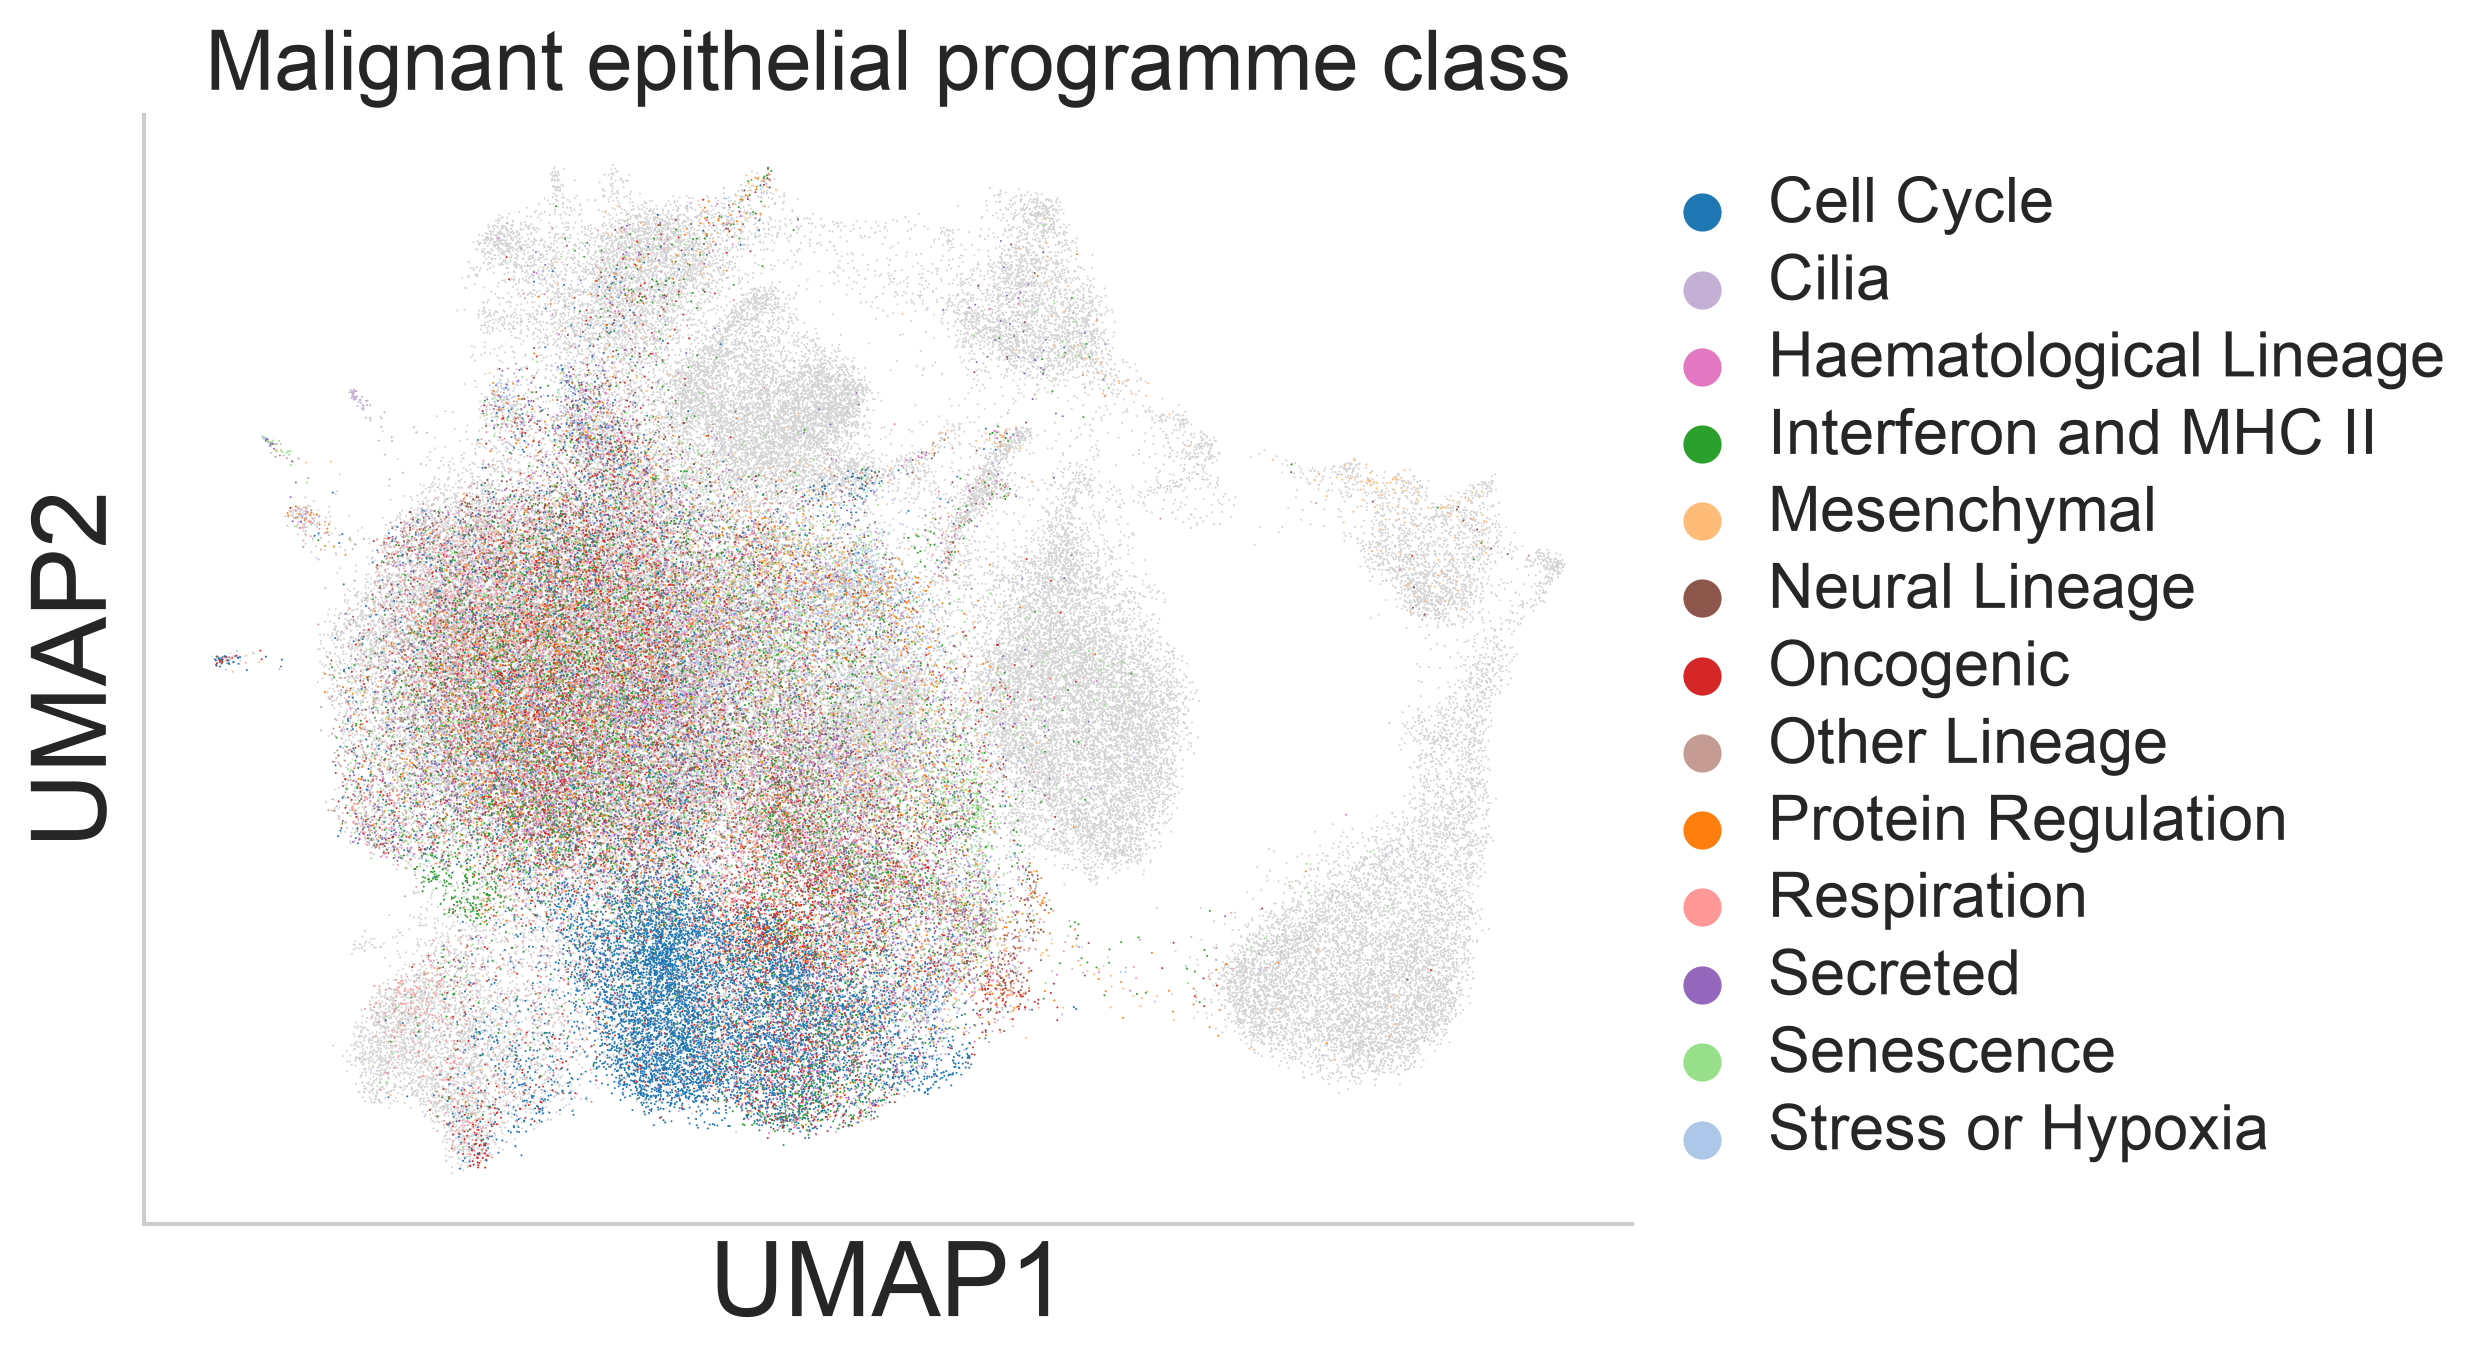

In [157]:
sc.pl.umap(
    epi,
    color=plot_col,
    frameon=True,
    legend_loc="right margin",
    title="Malignant epithelial programme class",
    na_color="lightgrey",
    na_in_legend=False,
    palette=hallmark_palette,
    show=False,
)

ax = plt.gca()
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)
ax.tick_params(axis="both", labelsize=12)

legend = ax.get_legend()

if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)
    for handle in legend.legend_handles:
        handle.set_sizes([70])

plt.savefig(fig_dir / "gavish_programme_umap.png", dpi=300, bbox_inches="tight")
plt.show()

## Staircase heatmap — meta-programme activity per cell

In [158]:
# cells grouped by their dominant class, ordered within a class by that class's score
cell_labels_x = [h for h in hallmark_order_all if h in set(dominant_class)]

In [159]:
chunks = []

In [160]:
cell_boundaries = [0]

In [161]:
cell_labels = []

In [162]:
for hallmark in cell_labels_x:

    cells = dominant_class.index[dominant_class == hallmark]

    if len(cells) == 0:
        continue

    order = hallmark_scores.loc[cells, hallmark].sort_values(ascending=False).index
    chunks.append(robust_scores.loc[order])

    cell_boundaries.append(cell_boundaries[-1] + len(order))
    cell_labels.append(hallmark)

In [163]:
heatmap_df = pd.concat(chunks)

In [164]:
hallmark_strip = np.concatenate(
    [np.full(len(chunk), label) for chunk, label in zip(chunks, cell_labels)]
)

In [165]:
heatmap_df.shape

(60413, 41)

In [166]:
matrix = heatmap_df[mp_ordered].to_numpy().T

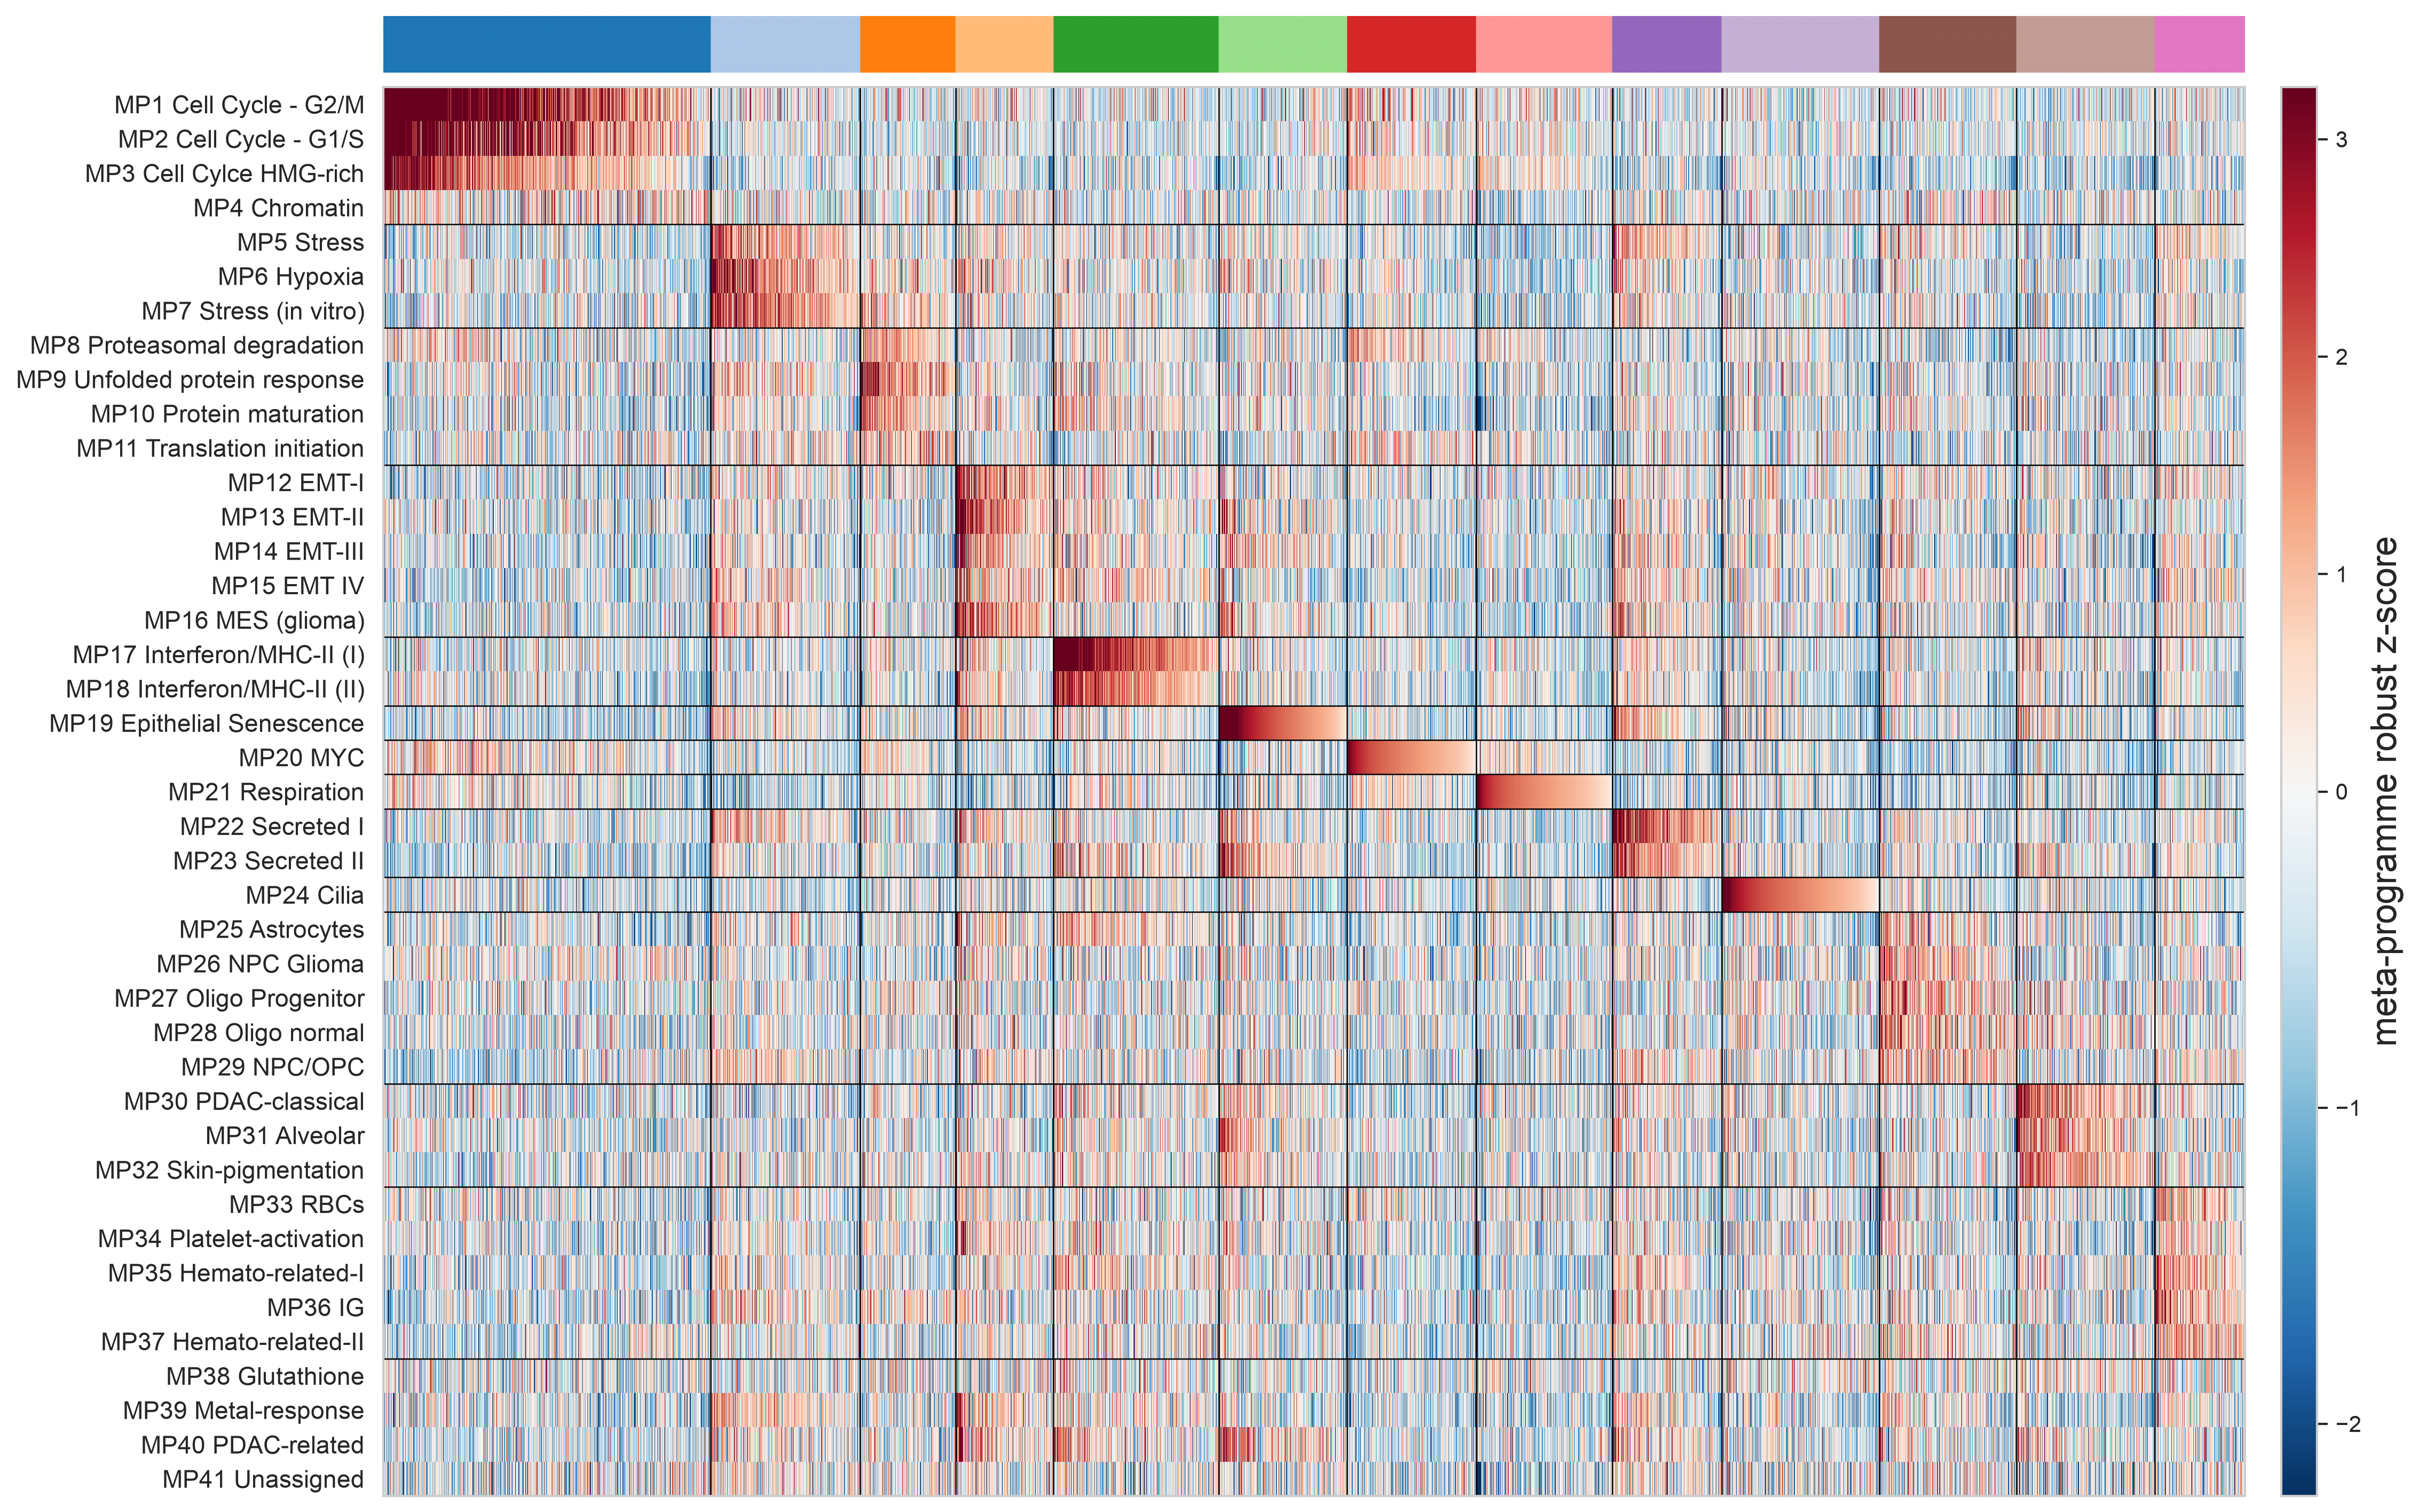

In [167]:
fig = plt.figure(figsize=(15, 12))
gs = gridspec.GridSpec(2, 1, height_ratios=[0.4, 10], hspace=0.02)

ax_strip = fig.add_subplot(gs[0])
ax_strip.imshow(np.array([hallmark_palette[h] for h in hallmark_strip])[None, :, :], aspect="auto")
ax_strip.axis("off")

ax = fig.add_subplot(gs[1])

norm = TwoSlopeNorm(
    vmin=np.percentile(matrix, 1), vcenter=0, vmax=np.percentile(matrix, 99)
)

im = ax.imshow(matrix, aspect="auto", cmap="RdBu_r", norm=norm, interpolation="none")

ax.set_yticks(range(len(mp_ordered)))
ax.set_yticklabels(mp_ordered, fontsize=11)
ax.set_xticks([])
ax.grid(False)

for boundary in cell_boundaries[1:-1]:
    ax.axvline(boundary - 0.5, color="black", linewidth=0.6)

for start, _ in mp_row_boundaries.values():
    if start > 0:
        ax.axhline(start - 0.5, color="black", linewidth=0.6)

tick_positions = [
    (cell_boundaries[i] + cell_boundaries[i + 1]) / 2 for i in range(len(cell_labels))
]

ax_strip.set_xticks(tick_positions)
ax_strip.set_xticklabels(cell_labels, fontsize=8, rotation=45, ha="left")
ax_strip.xaxis.tick_top()

fig.canvas.draw()
pos = ax.get_position()

cax = fig.add_axes([pos.x1 + 0.015, pos.y0, 0.015, pos.height])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label("meta-programme robust z-score")

plt.savefig(fig_dir / "gavish_mp_staircase_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## programme class by meta-programme bubble plot



For each class and meta-programme, the colour is the highest cluster-level mean
z-score among the clusters assigned to that class, and the bubble size is the
active-cell fraction of that same cluster. Taking the maximum rather than the
mean keeps two different states inside one class visible.

In [168]:
hallmarks_to_plot = [
    h for h in hallmark_labels_x if h not in (no_dominant, "Unassigned")
]

In [169]:
bubble_rows = []

In [170]:
bubble_row_boundaries = {}

In [171]:
counter = 0

In [172]:
for hallmark in gavish_hallmarks:

    if hallmark == "Unassigned" or hallmark not in hallmarks_to_plot:
        continue

    present = [mp for mp in gavish_hallmarks[hallmark] if mp in robust_scores.columns]

    if not present:
        continue

    bubble_row_boundaries[hallmark] = (counter, counter + len(present))
    bubble_rows.extend(present)
    counter += len(present)

In [173]:
hallmarks_to_plot

['Cell Cycle',
 'Stress or Hypoxia',
 'Mesenchymal',
 'Interferon and MHC II',
 'Secreted',
 'Cilia',
 'Haematological Lineage']

In [174]:
bubble_z = pd.DataFrame(index=hallmarks_to_plot, columns=bubble_rows, dtype=float)

In [175]:
bubble_frac = pd.DataFrame(index=hallmarks_to_plot, columns=bubble_rows, dtype=float)

In [176]:
bubble_cluster = pd.DataFrame(index=hallmarks_to_plot, columns=bubble_rows, dtype=object)

In [177]:
for hallmark in hallmarks_to_plot:

    clusters = cluster_to_hallmark[cluster_to_hallmark == hallmark].index.tolist()

    for mp in bubble_rows:

        cluster_z = mean_z.loc[clusters, mp].dropna()

        if cluster_z.empty:
            continue

        best = cluster_z.idxmax()

        bubble_z.loc[hallmark, mp] = cluster_z.loc[best]
        bubble_frac.loc[hallmark, mp] = frac_active.loc[best, mp]
        bubble_cluster.loc[hallmark, mp] = best

In [178]:
bubble_cluster.to_csv(df_dir / "gavish_bubble_defining_cluster.csv")

In [179]:
DOT_SCALE = 300   # marker area for a cluster in which every cell is active

In [180]:
n_hallmarks = len(hallmarks_to_plot)

In [181]:
n_mps = len(bubble_rows)

In [182]:
xx, yy = np.meshgrid(np.arange(n_hallmarks), np.arange(n_mps))

In [183]:
colors = bubble_z.to_numpy(dtype=float).T.ravel()

In [184]:
sizes = bubble_frac.to_numpy(dtype=float).T.ravel() * DOT_SCALE

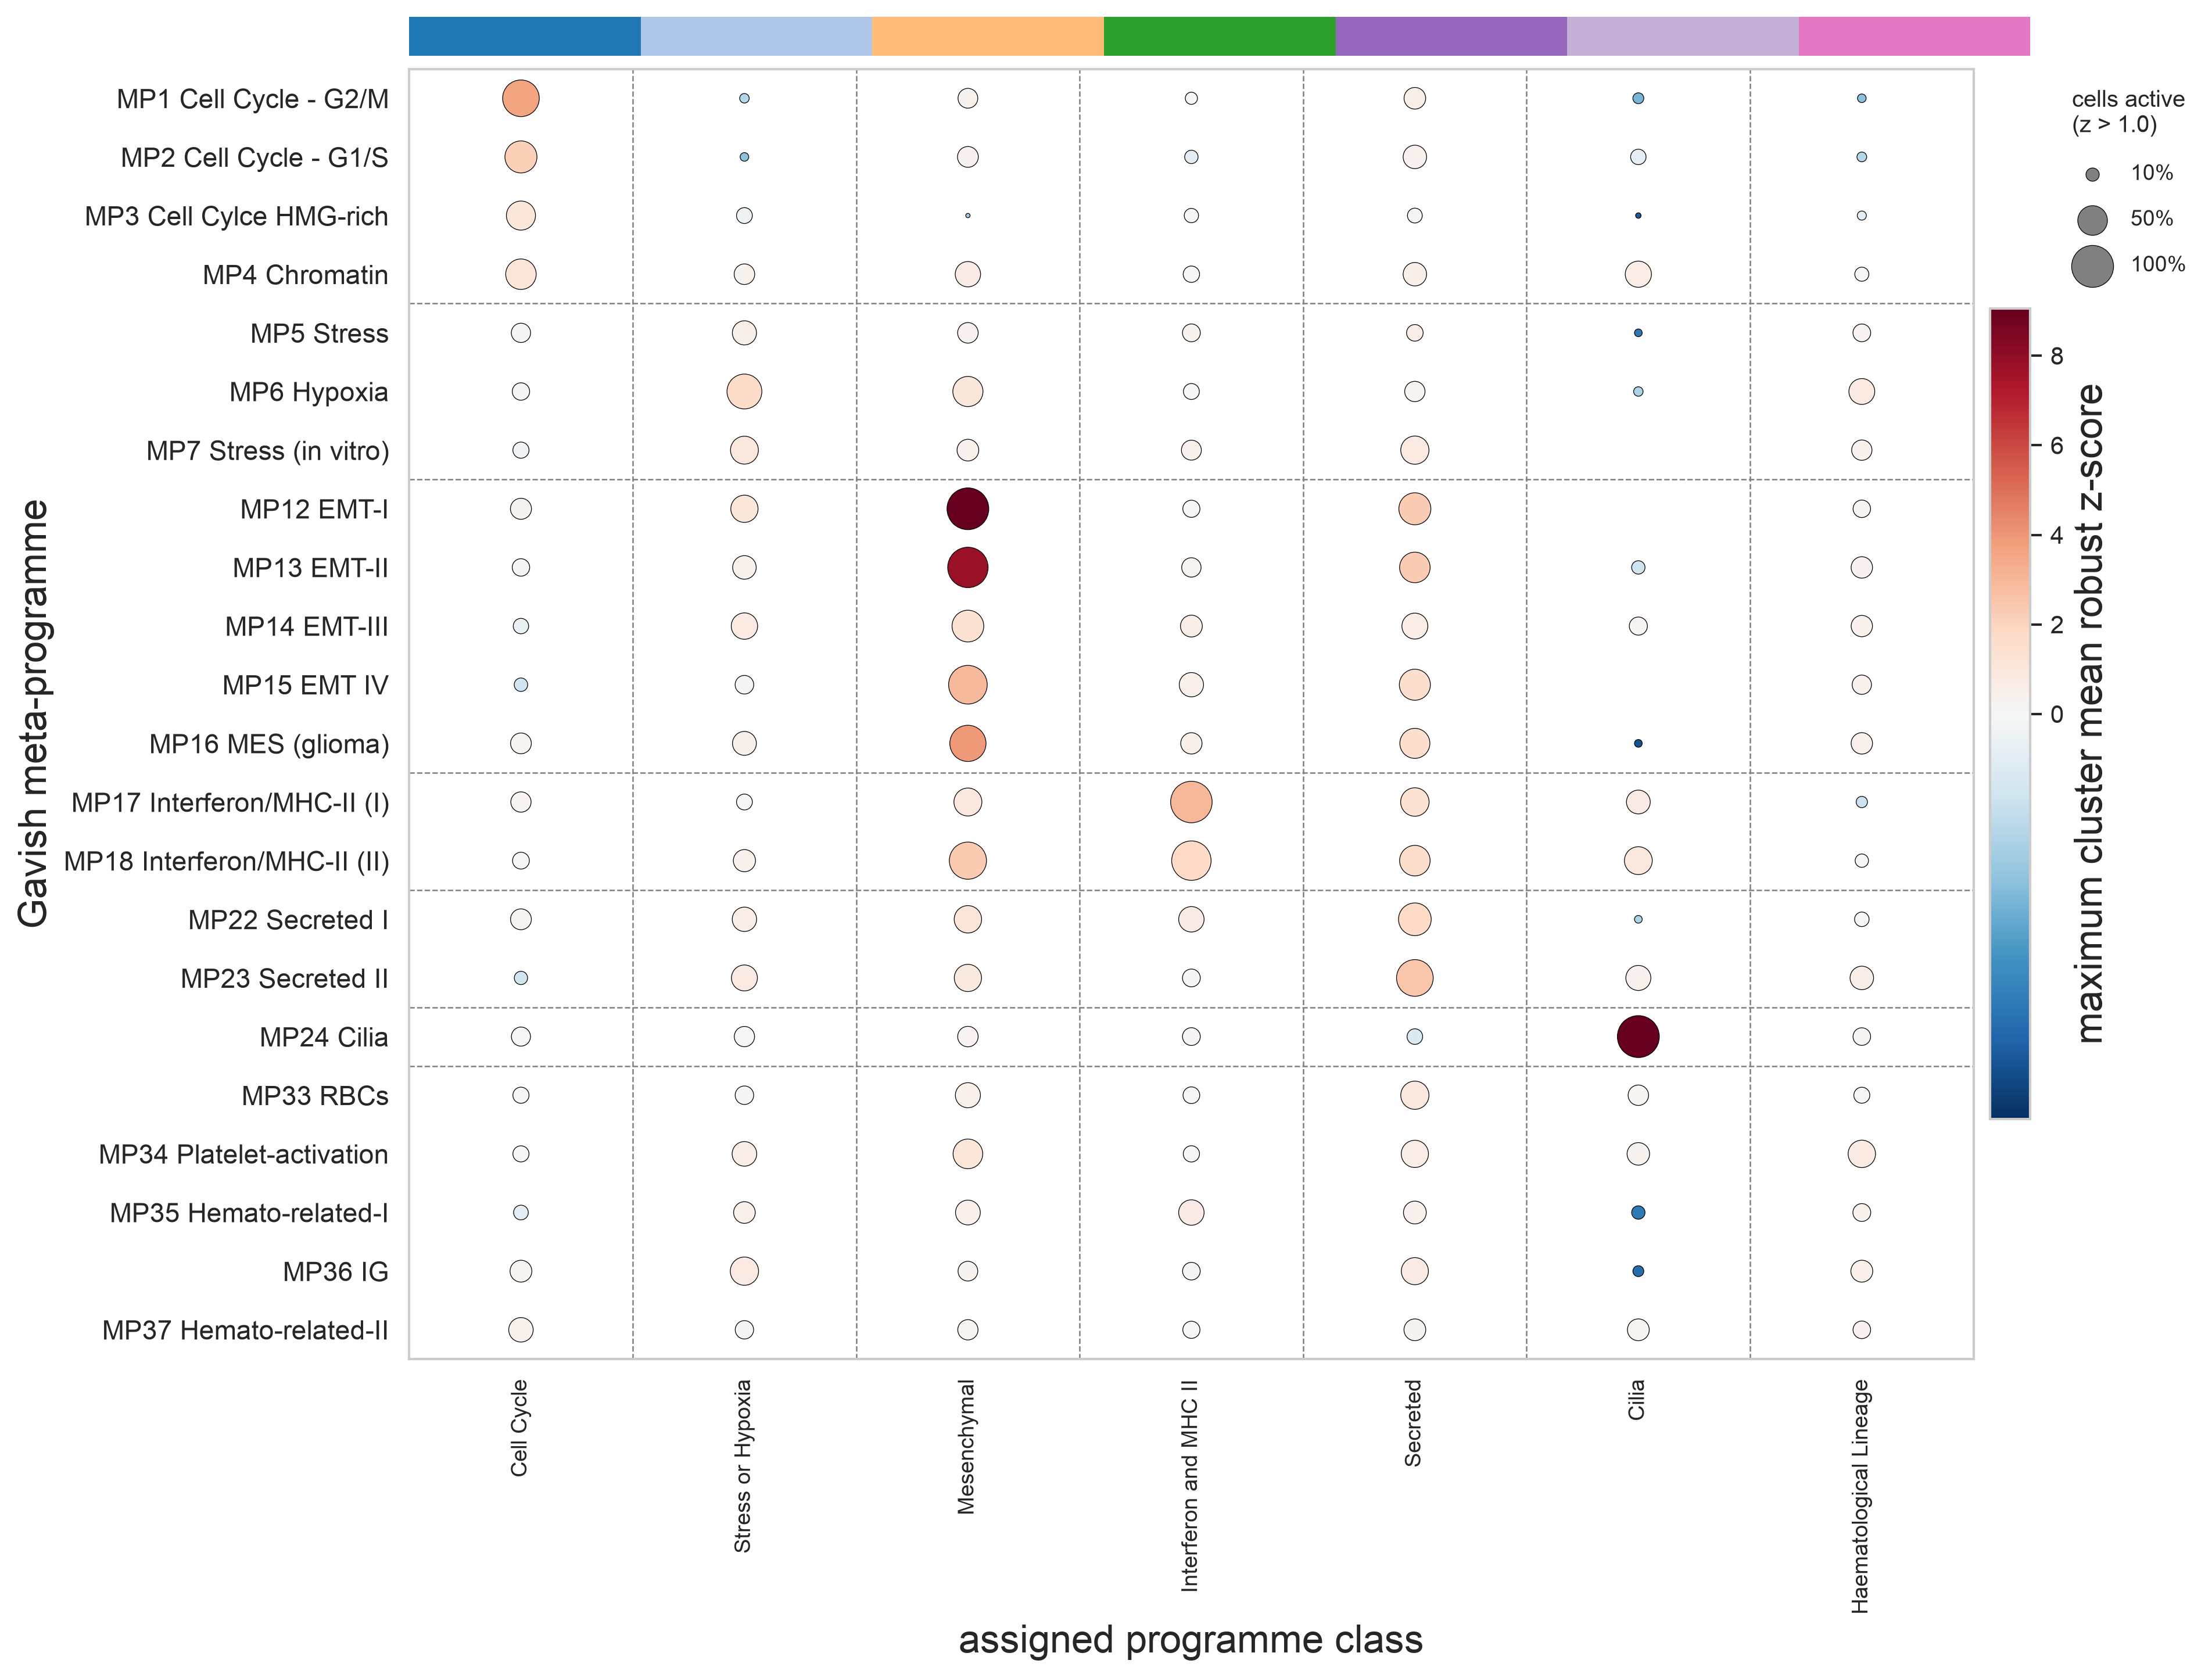

In [185]:
fig = plt.figure(figsize=(max(12, n_hallmarks * 0.8), max(10, n_mps * 0.3)))
gs = gridspec.GridSpec(2, 1, height_ratios=[0.3, 10], hspace=0.02)

ax_strip = fig.add_subplot(gs[0])
ax_strip.imshow(np.array([hallmark_palette[h] for h in hallmarks_to_plot])[None, :, :], aspect="auto")
ax_strip.axis("off")
ax_strip.set_xlim(-0.5, n_hallmarks - 0.5)
ax_strip.set_xticks(np.arange(n_hallmarks))
ax_strip.set_xticklabels(hallmarks_to_plot, fontsize=9, rotation=45, ha="left")
ax_strip.xaxis.tick_top()

ax = fig.add_subplot(gs[1])

finite = colors[np.isfinite(colors)]

norm = TwoSlopeNorm(
    vmin=np.nanpercentile(finite, 1), vcenter=0, vmax=np.nanpercentile(finite, 99)
)

points = ax.scatter(
    xx.ravel(), yy.ravel(), s=sizes, c=colors, cmap="RdBu_r", norm=norm,
    edgecolor="black", linewidth=0.3,
)

ax.set_xlim(-0.5, n_hallmarks - 0.5)
ax.set_ylim(-0.5, n_mps - 0.5)
ax.invert_yaxis()
ax.set_xticks(range(n_hallmarks))
ax.set_xticklabels(hallmarks_to_plot, fontsize=9, rotation=90)
ax.set_yticks(range(n_mps))
ax.set_yticklabels(bubble_rows, fontsize=11)
ax.set_xlabel("assigned programme class")
ax.set_ylabel("Gavish meta-programme")
ax.grid(False)

for boundary in range(1, n_hallmarks):
    ax.axvline(boundary - 0.5, color="grey", linewidth=0.6, linestyle="--")

for start, _ in bubble_row_boundaries.values():
    if start > 0:
        ax.axhline(start - 0.5, color="grey", linewidth=0.6, linestyle="--")

cbar = fig.colorbar(points, ax=ax, pad=0.01, fraction=0.025)
cbar.set_label("maximum cluster mean robust z-score")

for fraction in [0.1, 0.5, 1.0]:
    ax.scatter([], [], s=fraction * DOT_SCALE, color="grey", edgecolor="black",
               linewidth=0.3, label=f"{int(fraction * 100)}%")

ax.legend(
    title=f"cells active\n(z > 1.0)",
    loc="upper left", bbox_to_anchor=(1.05, 1.0), frameon=False, labelspacing=1.2,
)

plt.savefig(fig_dir / "gavish_mp_class_bubbleplot.png", dpi=300, bbox_inches="tight")
plt.show()

## Patient-level programme-class composition across clinical conditions

Technical samples remain separate for scoring, but replicate libraries from the
same patient and condition are pooled before proportions are calculated. Each
patient-condition unit therefore contributes once to the Kruskal–Wallis tests.
Holm adjustment controls family-wise error across the 13 programme classes; a
non-significant result is not evidence that the condition distributions are equal.

In [186]:
condition_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}

In [187]:
# Figure 1c uses the dominant relative class, over every scored malignant cell
distribution = epi.obs.loc[dominant_class.index, ["condition", "Gavish_dominant_class"]].copy()
distribution.columns = ["condition", "hallmark"]

In [188]:
distribution["condition"] = distribution["condition"].astype(str)
distribution["hallmark"] = distribution["hallmark"].astype(str)

In [189]:
hallmarks_present = [h for h in cell_labels_x if h in set(distribution["hallmark"])]

In [190]:
conditions_present = [c for c in ["TN", "HER2+", "ER+"] if c in set(distribution["condition"])]

In [191]:
hallmarks_present

['Cell Cycle',
 'Stress or Hypoxia',
 'Protein Regulation',
 'Mesenchymal',
 'Interferon and MHC II',
 'Senescence',
 'Oncogenic',
 'Respiration',
 'Secreted',
 'Cilia',
 'Neural Lineage',
 'Other Lineage',
 'Haematological Lineage']

In [192]:
conditions_present

['TN', 'HER2+', 'ER+']

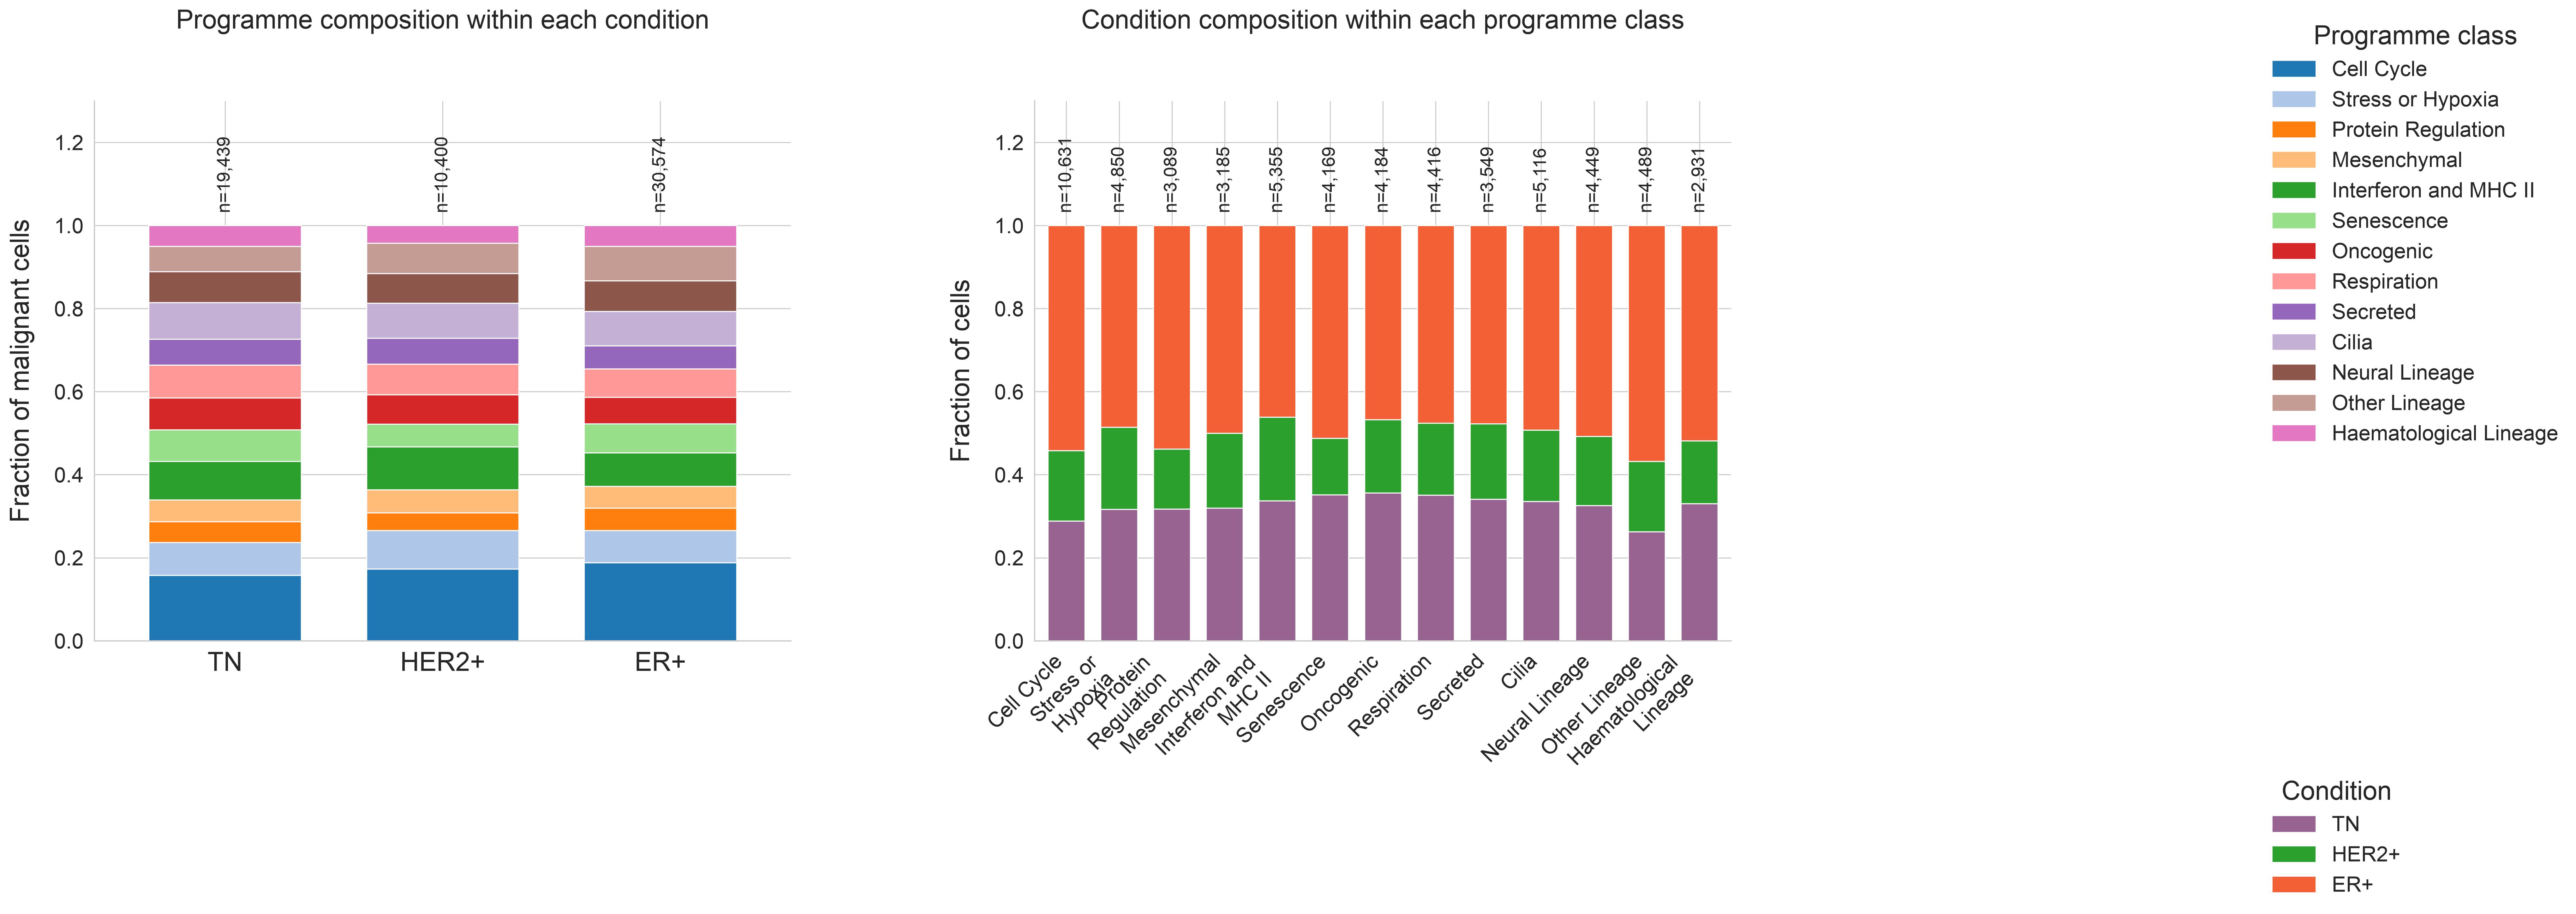

In [193]:
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

within_condition = (
    pd.crosstab(distribution["condition"], distribution["hallmark"], normalize="index")
    .reindex(index=conditions_present, columns=hallmarks_present)
    .fillna(0)
)

within_condition.plot(
    kind="bar", stacked=True, ax=axes[0], width=0.7, legend=False,
    color=[hallmark_palette[h] for h in within_condition.columns],
)

axes[0].set_title("Programme composition within each condition", fontsize=20, pad=55)
axes[0].set_xlabel("")
axes[0].set_ylabel("Fraction of malignant cells", fontsize=20, labelpad=15)
axes[0].tick_params(axis="x", rotation=0, labelsize=20)
axes[0].tick_params(axis="y", labelsize=16)
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].set_ylim(0, 1.30)

n_condition = distribution["condition"].value_counts()

for i, condition in enumerate(within_condition.index):
    axes[0].text(i, 1.03, f"n={n_condition[condition]:,}", ha="center", va="bottom",
                 rotation=90, fontsize=14)

within_hallmark = (
    pd.crosstab(distribution["hallmark"], distribution["condition"], normalize="index")
    .reindex(index=hallmarks_present, columns=conditions_present)
    .fillna(0)
)

within_hallmark.plot(
    kind="bar", stacked=True, ax=axes[1], width=0.7, legend=False,
    color=[condition_palette[c] for c in within_hallmark.columns],
)

axes[1].set_title("Condition composition within each programme class", fontsize=20, pad=55)
axes[1].set_xlabel("")
axes[1].set_ylabel("Fraction of cells", fontsize=20, labelpad=15)
axes[1].set_xticklabels([textwrap.fill(h, width=14) for h in within_hallmark.index],
                        rotation=45, ha="right", fontsize=16)
axes[1].tick_params(axis="y", labelsize=16)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].set_ylim(0, 1.30)

n_hallmark = distribution["hallmark"].value_counts()

for i, hallmark in enumerate(within_hallmark.index):
    axes[1].text(i, 1.03, f"n={n_hallmark.get(hallmark, 0):,}", ha="center", va="bottom",
                 rotation=90, fontsize=14)

legend_one = fig.legend(
    [plt.Rectangle((0, 0), 1, 1, color=hallmark_palette[h]) for h in hallmarks_present],
    hallmarks_present, title="Programme class", title_fontsize=20,
    loc="upper left", bbox_to_anchor=(1.01, 0.95), fontsize=16, frameon=False,
)

fig.legend(
    [plt.Rectangle((0, 0), 1, 1, color=condition_palette[c]) for c in conditions_present],
    conditions_present, title="Condition", title_fontsize=20,
    loc="upper left", bbox_to_anchor=(1.01, 0.95 - 0.055 * (len(hallmarks_present) + 1.5)),
    fontsize=16, frameon=False,
)

fig.subplots_adjust(left=0.06, right=0.78, top=0.85, bottom=0.28, wspace=0.35)

plt.savefig(fig_dir / "gavish_programme_condition_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [194]:
# free the large intermediates; nothing below uses them
del malignant
gc.collect()

10976

In [195]:
within_condition.to_csv(df_dir / "gavish_programme_fraction_by_condition.csv")

In [196]:
# Biological inference uses one patient-condition composition per row. Cells remain scored within technical samples above, but replicate libraries from the same patient and condition are pooled before calculating proportions.
assignment_frame = epi.obs.loc[
    dominant_class.index, [donor_key, "condition", "Gavish_dominant_class"]
].copy()
assignment_frame[donor_key] = assignment_frame[donor_key].astype(str)
assignment_frame["condition"] = assignment_frame["condition"].astype(str)
assignment_frame["Gavish_dominant_class"] = assignment_frame["Gavish_dominant_class"].astype(str)

composition_counts = pd.crosstab(
    [assignment_frame[donor_key], assignment_frame["condition"]],
    assignment_frame["Gavish_dominant_class"],
)
composition = (
    composition_counts.div(composition_counts.sum(axis=1), axis=0)
    .reset_index()
)

In [197]:
assert not composition.duplicated([donor_key, "condition"]).any()
cross_condition = composition.groupby(donor_key, observed=True)["condition"].nunique()
assert (cross_condition <= 1).all(), (
    "condition-level Kruskal test assumes independent patients; "
    f"patients spanning conditions: {cross_condition[cross_condition > 1].index.tolist()}"
)
composition.groupby("condition", observed=True).size()

condition
ER+      16
HER2+     6
TN        6
dtype: int64

In [198]:
rows = []

In [199]:
for hallmark in [c for c in composition.columns if c not in {donor_key, "condition"}]:

    groups = [g[hallmark].to_numpy() for _, g in composition.groupby("condition", observed=True)]
    groups = [g for g in groups if len(g) > 1]

    if len(groups) < 2:
        continue

    rows.append({"hallmark": hallmark, "p_kruskal": kruskal(*groups).pvalue})

In [200]:
kruskal_results = pd.DataFrame(rows, columns=["hallmark", "p_kruskal"])

In [201]:
len(composition)

28

In [202]:
if kruskal_results.empty:
    print("no programme class has more than one patient in at least two conditions")

else:
    kruskal_results = kruskal_results.sort_values("p_kruskal").reset_index(drop=True)

    # Holm-Bonferroni across the programme classes tested
    kruskal_results["p_holm"] = np.minimum(
        1, kruskal_results["p_kruskal"] * (len(kruskal_results) - kruskal_results.index)
    ).cummax()

    print(kruskal_results.round(4))

                  hallmark  p_kruskal  p_holm
0            Other Lineage     0.0079  0.1025
1               Senescence     0.0439  0.5272
2        Stress or Hypoxia     0.0622  0.6841
3   Haematological Lineage     0.2115  1.0000
4              Mesenchymal     0.2498  1.0000
5           Neural Lineage     0.3046  1.0000
6                 Secreted     0.5363  1.0000
7               Cell Cycle     0.5528  1.0000
8    Interferon and MHC II     0.5665  1.0000
9       Protein Regulation     0.6600  1.0000
10             Respiration     0.6690  1.0000
11               Oncogenic     0.8232  1.0000
12                   Cilia     0.8782  1.0000


In [203]:
kruskal_results.to_csv(df_dir / "gavish_programme_condition_kruskal.csv", index=False)

## Mesenchymal programme score

In [204]:
# EMT/mesenchymal activity used in 003c, averaged over the class's meta-programmes
mesenchymal_mps = [mp for mp in gavish_hallmarks["Mesenchymal"] if mp in robust_scores.columns]

In [205]:
len(mesenchymal_mps), len(gavish_hallmarks["Mesenchymal"])

(5, 5)

In [206]:
# mesenchymal activity: the within-sample robust-z scores of MP12-MP16 are averaged and the resulting class score is robust-z standardised within each sample. This is therefore relative within-sample mesenchymal activity, not an absolute amplitude that can be compared across patients.
epi.obs["Gavish_Mesenchymal_score"] = np.nan
epi.obs.loc[class_scores.index, "Gavish_Mesenchymal_score"] = (
    class_scores["Mesenchymal"].to_numpy()
)

assert np.allclose(
    epi.obs.loc[class_scores.index, "Gavish_Mesenchymal_score"].to_numpy(dtype=float),
    epi.obs.loc[class_scores.index, "Gavish_Mesenchymal"].to_numpy(dtype=float),
)

In [207]:
epi.obs["Gavish_Mesenchymal_score"].describe().round(3)

count    60413.000
mean         0.054
std          1.158
min         -4.733
25%         -0.664
50%          0.000
75%          0.685
max         18.580
Name: Gavish_Mesenchymal_score, dtype: float64

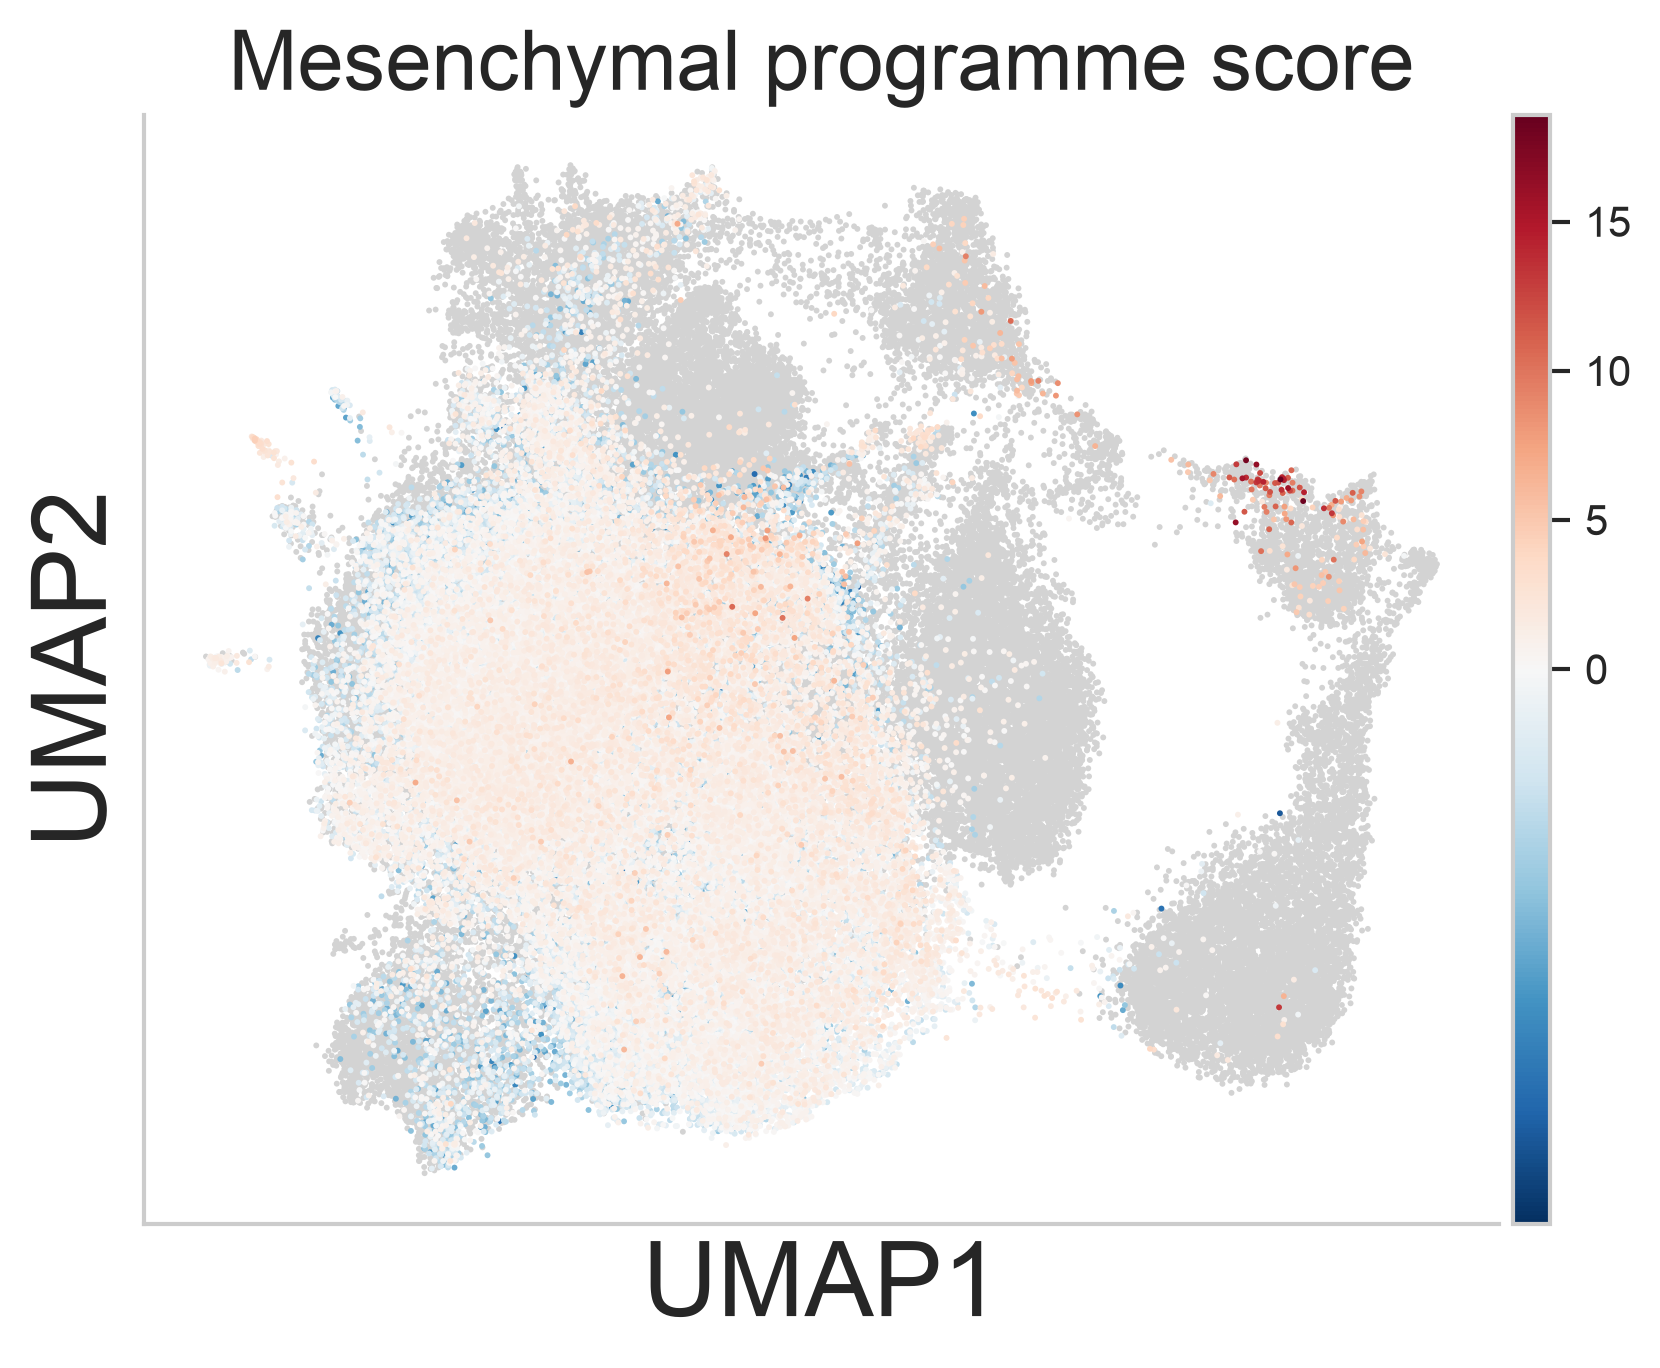

In [208]:
sc.pl.umap(
    epi,
    color="Gavish_Mesenchymal_score",
    frameon=True,
    title="Mesenchymal programme score",
    cmap="RdBu_r",
    vcenter=0,
    na_color="lightgrey",
    size=8,
    show=False,
)

ax = plt.gca()
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)
ax.tick_params(axis="both", labelsize=12)

plt.savefig(fig_dir / "gavish_mesenchymal_score_umap.png", dpi=300, bbox_inches="tight")
plt.show()

## Save

In [209]:
for col in ["Gavish_dominant_class", "Gavish_confident_class",
            "Gavish_high_activity_class", "Gavish_state_cluster"]:
    assert epi.obs.loc[~malignant_mask, col].astype(str).eq("non_malignant").all(), col

In [210]:
assert epi.obs.loc[robust_scores.index, "Gavish_state_cluster"].astype(str).ne("not_scored").all()

In [211]:
assert epi.obs.loc[cell_state.index, "Gavish_high_activity_class"].astype(str).ne("not_scored").all()

In [212]:
# nothing is saved until the assignment is internally consistent
assert epi.uns["gavish_assignment"]["gate_statistic"] == gate_statistic

print("\nfinal gavish assignment audit")
print(f"scored malignant cells:    {len(class_scores):,}")
print(f"dominant classes assigned: {epi.obs.loc[class_scores.index, 'Gavish_dominant_class'].notna().sum():,}")
print(f"activity threshold:        {activity_threshold:.4f}")
print(f"estimated fdr:             {selected_fdr:.3f}")
print(f"conservative fdr:          {selected_fdr_upper:.3f}")
print(f"score-gate pass:           {int(score_pass.sum()):,}")
print(f"post-recurrence retained:  {int(high_activity_retained.sum()):,}")
print(f"below score gate:          {int((~score_pass).sum()):,}")
print(f"below recurrence gate:     {int(score_pass.sum() - high_activity_retained.sum()):,}")
print(f"confident cells:           {len(assigned_confident):,}")
print(f"confident pooled fdr:      {pooled_fdr:.3f}")
print(f"classes without threshold: {sum(1 for h in class_scores.columns if not np.isfinite(confident_threshold.get(h, np.nan)))}")
print(f"gate statistic:            {gate_statistic}")


final gavish assignment audit
scored malignant cells:    60,413
dominant classes assigned: 60,413
activity threshold:        3.3739
estimated fdr:             0.086
conservative fdr:          0.100
score-gate pass:           7,310
post-recurrence retained:  6,324
below score gate:          53,103
below recurrence gate:     986
confident cells:           8,191
confident pooled fdr:      0.072
classes without threshold: 5
gate statistic:            maximum across the 13 within-sample re-standardised class scores


In [213]:
out_path = save_dir / "epithelial_gavish.h5ad"

In [214]:
tmp_path = out_path.with_suffix(".h5ad.tmp")

In [215]:
epi.write_h5ad(tmp_path, compression="gzip")

In [216]:
os.replace(tmp_path, out_path)

In [217]:
out_path.name

'epithelial_gavish.h5ad'

In [218]:
# check, that saved correctly

In [219]:
check = sc.read_h5ad(out_path, backed="r")

In [220]:
assert check.n_obs == epi.n_obs

In [221]:
assert check.n_vars == epi.n_vars

In [222]:
check.shape

(129599, 27357)

In [223]:
del check

In [224]:
gc.collect()

0

In [228]:
import session_info

In [229]:
session_info.show()

/opt/miniconda3/envs/cap/lib/python3.11/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  mod_version = _find_version(mod.__version__)
